> **v6 changes (on top of v5)** — diagnosis: v5 scored ~0.93 on its CV but 0.855 on the public leaderboard. Unlabeled features show *why*: for leopard, the nearest training identity of a CV known query is a huge identity (>=30 images) 86-90 % of the time, but only ~42 % for test queries, i.e. the test contains far more queries of rarely seen individuals than an image-weighted CV can produce.
> 1. **Rare-identity validation/training scheme `r<seed>`** (`RARE_SEEDS`, default `3`): known identities are validated with thinned galleries (1-6 bursts). It is used for model fitting and reporting exactly like the `s<seed>` schemes; `RARE_SEEDS=""` restores v5.
> 2. **`PRIOR_SHIFT` default `off`**: the two available estimates of the test new-share disagree (similarity mixture: ~0.27 for leopard; size-shift re-weighting: ~0.5), so the prior is no longer moved on one of them.
> 3. Outputs go to `out_v6/` (v5 files are not overwritten); section 6a prints the size-shift table and the domain AUC; the results section reports test-like and rare schemes separately.

# Wildlife Re-ID — v5: validation-corrected pipeline

Predict up to five identities per test image (known identity of the same species, or `new_individual`), scored by MAP@5, using only the provided MiewID and SIFT features.

| Version | What it is |
|---|---|
| **V1** | raw MiewID cosine + tuned `new_individual` threshold |
| **V2** | V1 + PCA/whitening, re-ranking, SIFT+RANSAC, viewpoint bonus (hand-tuned blend) |
| **V3** | learned identity ranker (gradient-boosted trees on pairwise evidence) + learned `P(new)` |
| **V4** | V3 + transductive evidence from neighbouring test queries (a new animal usually shows up several times) |

## What changed in this revision (v5), and why
This revision applies the findings of the audit of `submission6_23_11`. The model code is unchanged; **the validation that every tuned number depends on was replaced.**

| # | Problem found in the previous version | Fix in this notebook |
|---|---|---|
| 1 | `rand` folds leaked near-duplicates across folds (2.5 % / 5.1 % of queries had a >0.9-similar gallery image vs 0.2 % / 0.8 % in test) | **burst-grouped hold-out**: a validation image never has a same-identity gallery image above θ = 0.80 (asserted) |
| 2 | `hard` folds over-corrected (known top-1 fell from 0.85 to ~0.55) and models were trained on a 50/50 mix of two regimes, neither like test | **one test-like scheme** (held-out identities + burst-grouped known identities), 3 seeds; `hard` is kept as an *evaluation-only stress test* and never used for training |
| 3 | uncontrolled composition (new share 0.27 vs 0.45 by species, 0.20–0.63 by fold, a 391-image identity = 16 % of new queries) | identity-size cap (120), new share controlled per species, ±2 pts per fold |
| 4 | τ tuned in-sample (V1/V2/F) while learned rows were out-of-fold; τ transferred as the mean of two unlike schemes | **cross-fitted τ**; the in-sample value is still logged to show the optimism |
| 5 | projection strength α chosen on the leaky folds | α re-selected on test-like folds, with a cross-fit optimism diagnostic |
| 6 | new-individual share assumed (0.40) and the shift check was circular | share **estimated** from the test similarity distribution, with an uncertainty band; optional, conservative prior-shift correction and a sensitivity table |
| 7 | query-pool statistics differ between CV and test | logged per feature in the shift report |
| 8 | ablation gains read off a single scheme | ablation reported as mean ± std over seeds, plus the stress test |
| 9 | minor: in-sample permutation importance, viewpoint/bucket fed as ordinals, hard-coded paths | held-out importance, categorical features, `DATA_DIR` resolved from the environment |

**Compute note.** New folds change the (query, gallery) pairs, so SIFT matching is recomputed for pairs not already in `cache/` (3 seeds + stress ≈ 2× the previous cost). For a quick pass use `CV_SEEDS=0 RUN_STRESS=0 FAST=1`.

In [1]:
import os, sys, json, time, glob, hashlib, warnings, threading
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 0
np.random.seed(SEED)
T_START = time.time()
def log(*a): print(f"[{time.time() - T_START:6.0f}s]", *a, flush=True)

def _env_int(name, default): return int(os.environ.get(name, default))

def _resolve_data_dir():
    for c in [os.environ.get("DATA_DIR"), "C:/Users/Mayank/Downloads/projectwild3/reid_student_data_main", "reid_student_data_main", "."]:
        if c and os.path.isfile(os.path.join(c, "train.csv")): return c
    raise FileNotFoundError("train.csv not found - set the DATA_DIR environment variable to the folder that contains it.")
DATA_DIR   = _resolve_data_dir()
PARENT_DIR = os.environ.get("PARENT_DIR", os.path.dirname(os.path.abspath(DATA_DIR)))
CACHE_DIR, FIG_DIR = os.environ.get("CACHE_DIR", "cache"), "figures"
OUT_DIR    = os.environ.get("OUT_DIR", "out_v6")
for d in (CACHE_DIR, FIG_DIR, OUT_DIR): os.makedirs(d, exist_ok=True)

NEW, SPECIES = "new_individual", ["hyena", "leopard"]
SP_ID = {s: i for i, s in enumerate(SPECIES)}

# ---------- pipeline settings ----------
N_FOLDS        = _env_int("N_FOLDS", 4)          # 4 folds: val/gallery ratio 1:3, closest to test/train = 0.39
# ---- test-like validation design (see section 2) ----
CV_SEEDS       = tuple(int(x) for x in os.environ.get("CV_SEEDS", "0,1,2").split(","))   # independent partitions; models are trained on all of them
RUN_STRESS     = os.environ.get("RUN_STRESS", "1") == "1"       # evaluation-only 'hard' scheme (never used for training)
# ---- v6: rare-identity validation scheme(s) (see section 2). RARE_SEEDS="" restores the v5 behaviour.
RARE_SEEDS     = tuple(int(x) for x in os.environ.get("RARE_SEEDS", "3").split(",") if x.strip())
RARE_P_THIN    = {"hyena": 0.3, "leopard": 0.8}                  # per species: share of eligible known identities whose gallery is thinned (tuned so the CV looks like the test, see 6a)
for _kv in os.environ.get("RARE_P_THIN", "").split(","):          # override, e.g. RARE_P_THIN="hyena:0.5,leopard:1.0"
    if ":" in _kv: RARE_P_THIN[_kv.split(":")[0].strip()] = float(_kv.split(":")[1])
RARE_KEEP      = tuple(int(x) for x in os.environ.get("RARE_KEEP", "1,2,3,4,6").split(","))   # gallery keeps this many burst clusters of the thinned identity
THETA, PI_NEW, CAP_NEW = 0.80, 0.40, 120                        # burst threshold (cosine), target share of images in new identities, max size of a 'new' identity
NEW_QUERY_FRAC = PI_NEW                                         # used by the stress folds
PRIOR_SHIFT    = os.environ.get("PRIOR_SHIFT", "off")          # off | auto (conservative, within the estimated band) | force (point estimate)
PCA_DIM        = _env_int("PCA_DIM", 512)
RERANK_K1, RERANK_K2, RERANK_LAM = 20, 6, 0.3
CAND_K, TOP_M_SIFT = _env_int("CAND_K", 300), _env_int("TOP_M_SIFT", 150)
SIFT_RATIO, RANSAC_THRESH, RANSAC_ITERS = 0.78, 5.0, 2000
KN             = 5
NN_STRONG      = 8
TOP_ID         = _env_int("TOP_ID", 30)
TOP_L          = _env_int("TOP_L", 10)
CAND_LDA       = _env_int("CAND_LDA", 60)
ALPHAS         = [1.0, 0.6, 0.35, 0.2, 0.1, 0.05, 0.02, 0.01]
FAST           = os.environ.get("FAST", "0") == "1"
MODEL_FOLDS    = 5
TOP_M_EFF      = TOP_M_SIFT + CAND_LDA
SUBMIT_VERSION = "v4"
assert CAND_K >= TOP_M_EFF

# V2 hand-tuned parameters from the previous notebook (full precision file is used if present)
BEST_PARAMS = dict(w_rerank=0.2812, w_sift=0.1906, b_same=-0.0062, b_adj=0.0094, b_opp=0.0125, agg="top2", floor=3)
_cfgp = next((p for p in [os.path.join(d, "best_config_v2.json") for d in [".", DATA_DIR, PARENT_DIR]] if os.path.isfile(p)), None)
if _cfgp:
    BEST_PARAMS = json.load(open(_cfgp))["params"]; print("Loaded V2 params from", _cfgp)
assert SUBMIT_VERSION in ("v1", "v2", "v3", "v4")
print("DATA_DIR:", DATA_DIR, "| folds:", N_FOLDS, "| new-share target:", NEW_QUERY_FRAC, "| FAST:", FAST)

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name), dpi=150); plt.show()

Loaded V2 params from .\best_config_v2.json
DATA_DIR: C:/Users/Mayank/Downloads/projectwild3/reid_student_data_main | folds: 4 | new-share target: 0.4 | FAST: False


## 1. Load data

In [2]:
def load_data(d=DATA_DIR):
    tr = pd.read_csv(f"{d}/train.csv"); te = pd.read_csv(f"{d}/test.csv")
    ids = pd.read_csv(f"{d}/miewid_ids.csv")
    col = "id" if "id" in ids.columns else ids.columns[0]
    F = np.load(f"{d}/miewid_features.npy").astype(np.float32)
    pos = pd.Series(np.arange(len(ids)), index=ids[col].to_numpy())
    Xtr, Xte = F[pos.loc[tr.id.to_numpy()].to_numpy()], F[pos.loc[te.id.to_numpy()].to_numpy()]   # KeyError if ids misalign
    for df in (tr, te): df["viewpoint"] = df["viewpoint"].fillna("unk").astype(str)
    return tr, te, Xtr, Xte

tr, te, Xtr, Xte = load_data()
print(tr.shape, te.shape, Xtr.shape, Xte.shape)
CLASSES, code_tr = np.unique(tr.identity.astype(str).to_numpy(), return_inverse=True)   # one global code per identity
code_tr = code_tr.astype(np.int32)
print(tr.groupby("species").identity.agg(["size", "nunique"]))
print("identities with a single training image:", int((tr.identity.value_counts() == 1).sum()))

(7163, 4) (2791, 3) (7163, 2152) (2791, 2152)
         size  nunique
species               
hyena    1912      205
leopard  5251      345
identities with a single training image: 102


## 2. Metric and a test-like open-set cross-validation

**What the test set looks like** (from features only, no labels): almost no test image has a near-duplicate in train (top-1 cosine > 0.9 for 0.2 % / 0.8 % of hyena / leopard images, vs 3–12 % under a random image split), and about half of the test images have another *test* image as nearest neighbour. So test was built by holding out whole bursts/encounters, plus whole new identities that appear several times.

**Validation folds (per species, K folds, every image validated at most once):**
1. *New identities*: random identities (≤ `CAP_NEW` images) are held out **entirely** into one fold until ≈ `PI_NEW` of the images are covered → label `new_individual`.
2. *Known identities*: images are grouped into **burst clusters** (connected components of centred-cosine > θ inside an identity) and whole clusters are spread over folds, so no same-identity gallery image is above θ.
3. Identities with a single burst stay in the gallery (never validated).

(θ, π) were calibrated by matching the test distribution of top-1 similarity to the gallery (KS distance 0.06–0.09, vs 0.23+ for KFold / StratifiedKFold / GroupKFold / leave-one-out). The folds are asserted leak-free below.

In [3]:
NEG = -1e6

def ap5(pred, truth):
    """Average precision at 5 for one query (labels are strings)."""
    for k, p in enumerate(pred[:5]):
        if p == truth: return 1.0 / (k + 1)
    return 0.0

def map5(preds, truths):
    return float(np.mean([ap5(p, t) for p, t in zip(preds, truths)]))

assert abs(map5([["B", "C", "A"], ["x", "y", "N"], ["N"]], ["A", "N", "A"]) - (1/3 + 1/3 + 0) / 3) < 1e-12   # worked example sanity

def l2n(X): return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12)

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from scipy.stats import ks_2samp

ROWS_SP = {sp: np.flatnonzero((tr.species == sp).to_numpy()) for sp in SPECIES}
ID_SP   = {sp: tr.identity.astype(str).to_numpy(dtype=object)[ROWS_SP[sp]] for sp in SPECIES}

def _train_sim(sp):
    """Centred, L2-normalised MiewID cosine between train images (centring uses features only, no labels). Used only to BUILD/AUDIT the folds."""
    m_tr, m_te = (tr.species == sp).to_numpy(), (te.species == sp).to_numpy()
    Xs = l2n(np.vstack([Xtr[m_tr], Xte[m_te]])); Xc = l2n(Xs - Xs.mean(0))
    P = Xc[:int(m_tr.sum())]; S = P @ P.T; np.fill_diagonal(S, -9); return S

def burst_clusters(S, y, theta):
    """Connected components of {cos > theta} inside each identity = pseudo-encounters/bursts."""
    lab = np.zeros(len(y), int); off = 0
    for i in np.unique(y):
        idx = np.flatnonzero(y == i)
        if len(idx) == 1: c = np.zeros(1, int)
        else: _, c = connected_components(csr_matrix(S[np.ix_(idx, idx)] > theta), directed=False)
        lab[idx] = c + off; off += c.max() + 1
    return lab

def testlike_split(S, y, seed, k=N_FOLDS, theta=THETA, pi=PI_NEW, cap=CAP_NEW):
    """-> fold (n,) with -1 = never validated, and the set of identities held out entirely (the 'new' ones)."""
    n = len(y); rng = np.random.default_rng(seed)
    groups = burst_clusters(S, y, theta); fold = np.full(n, -1)
    for i in np.unique(y):                                   # known identities: spread whole burst clusters over folds
        idx = np.flatnonzero(y == i); gs = np.unique(groups[idx]); rng.shuffle(gs); off = rng.integers(k)
        if len(gs) > 1:
            for j, gk in enumerate(gs): fold[idx[groups[idx] == gk]] = (j + off) % k
    idu, cnt = np.unique(y, return_counts=True); tot, newids = 0, []
    for o in rng.permutation(len(idu)):                      # new identities: the whole identity goes into ONE fold
        if tot >= pi * n: break
        if cnt[o] > cap: continue
        newids.append(idu[o]); tot += cnt[o]
    for i, kk in zip(newids, rng.permutation(len(newids)) % k): fold[y == i] = kk
    return fold, set(newids)

def rare_split(S, y, seed, k=N_FOLDS, theta=THETA, pi=PI_NEW, cap=CAP_NEW, p_thin=None, keep=None, min_clusters=3):
    """v6 'rare-identity' scheme. Same contract as testlike_split, but for a random share p_thin of the known identities with >= min_clusters
    burst clusters, ALL BUT m (m drawn from `keep`) of its clusters are validated in ONE home fold. In that fold the identity's gallery has only m clusters
    (1-6 bursts instead of ~3/4 of the identity), mimicking test queries of rarely-seen individuals, which the image-weighted folds barely contain.
    The remaining m clusters are validated in the other folds, where the gallery is large. Leakage rules are unchanged (clusters are > theta-disconnected)."""
    p_thin = 0.5 if p_thin is None else p_thin; keep = RARE_KEEP if keep is None else keep
    n = len(y); rng = np.random.default_rng(seed + 1000)
    groups = burst_clusters(S, y, theta); fold = np.full(n, -1)
    load = np.zeros(k)                                         # images already assigned per fold: the home fold is the least loaded one (balances fold sizes)
    ids_ = np.unique(y); ids_ = ids_[np.argsort(-np.array([(y == i).sum() for i in ids_]), kind="stable")]   # big identities first
    for i in ids_:
        idx = np.flatnonzero(y == i); gs = np.unique(groups[idx]); rng.shuffle(gs); off = rng.integers(k)
        if len(gs) <= 1: continue
        if len(gs) >= min_clusters and rng.random() < p_thin:
            m = int(min(rng.choice(keep), len(gs) - 1)); home = int(np.argmin(load + 1e-3 * rng.random(k))); cut = len(gs) - m; oth = [f for f in range(k) if f != home]
            for gk in gs[:cut]: fold[idx[groups[idx] == gk]] = home
            for j, gk in enumerate(gs[cut:]): fold[idx[groups[idx] == gk]] = oth[(j + off) % len(oth)]
        else:
            for j, gk in enumerate(gs): fold[idx[groups[idx] == gk]] = (j + off) % k
        for f_ in range(k): load[f_] += (fold[idx] == f_).sum()
    idu, cnt = np.unique(y, return_counts=True); tot, newids = 0, []
    for o in rng.permutation(len(idu)):
        if tot >= pi * n: break
        if cnt[o] > cap: continue
        newids.append(idu[o]); tot += cnt[o]
    for i, kk in zip(newids, rng.permutation(len(newids)) % k): fold[y == i] = kk
    return fold, set(newids)

_SIMS = {sp: _train_sim(sp) for sp in SPECIES}
FOLDS = {}                                                   # scheme -> (fold per train row [-1 = never a query], held-out-identity flag per train row)
for seed in CV_SEEDS:
    fold = np.full(len(tr), -1); unseen = np.zeros(len(tr), bool)
    for sp in SPECIES:
        f_sp, newids = testlike_split(_SIMS[sp], ID_SP[sp], seed)
        fold[ROWS_SP[sp]] = f_sp; unseen[ROWS_SP[sp]] = np.isin(ID_SP[sp], list(newids))
    FOLDS[f"s{seed}"] = (fold, unseen)
for seed in RARE_SEEDS:                                       # v6: rare-identity schemes ('r<seed>'), used for training AND validation like 's<seed>'
    fold = np.full(len(tr), -1); unseen = np.zeros(len(tr), bool)
    for sp in SPECIES:
        f_sp, newids = rare_split(_SIMS[sp], ID_SP[sp], seed, p_thin=RARE_P_THIN[sp])
        fold[ROWS_SP[sp]] = f_sp; unseen[ROWS_SP[sp]] = np.isin(ID_SP[sp], list(newids))
    FOLDS[f"r{seed}"] = (fold, unseen)
TRS = tuple(FOLDS); PRIMARY = TRS[0]                         # TRS = schemes used for training AND validation

def audit_folds(name):
    """Hard leakage checks: disjoint, held-out identities absent from the gallery, known queries present in it, no burst/duplicate leakage."""
    fold, unseen = FOLDS[name]
    for sp in SPECIES:
        rows = ROWS_SP[sp]; f = fold[rows]; u = unseen[rows]; y = ID_SP[sp]; S = _SIMS[sp]
        for k in range(N_FOLDS):
            v = np.flatnonzero(f == k); g = np.flatnonzero(f != k)
            if len(v) == 0: continue
            assert not (set(v.tolist()) & set(g.tolist()))
            gl = set(y[g].tolist()); isnew = np.array([yy not in gl for yy in y[v]])
            assert (isnew == u[v]).all(), f"{name}/{sp}/fold {k}: held-out flag inconsistent with gallery membership"
            for i in set(y[v][isnew].tolist()): assert (f[y == i] == k).all(), "a new identity is split over folds"
            kn = v[~isnew]
            if len(kn):
                ms = np.where(y[kn][:, None] == y[g][None, :], S[np.ix_(kn, g)], -9).max(1)
                assert (ms > -9).all(), "known query without its identity in the gallery"
                assert ms.max() <= THETA + 1e-6, f"burst leakage: same-identity similarity {ms.max():.3f} > {THETA}"
            assert (S[np.ix_(v, g)] > 0.9999).sum() == 0, "exact duplicate vectors across val/gallery"
for name in TRS: audit_folds(name)
log(f"validation folds {TRS}: leakage audit PASSED (disjoint; held-out identities absent from gallery; no same-identity pair above {THETA})")

# reproducibility check against the standalone split notebook (splits_v1.csv), if present
for p in [os.environ.get("SPLITS_CSV"), "splits_v1.csv", os.path.join(OUT_DIR, "splits_v1.csv"), os.path.join(DATA_DIR, "splits_v1.csv")]:
    if p and os.path.isfile(p):
        ref = pd.read_csv(p); ok = (ref.id.to_numpy() == tr.id.to_numpy()).all() and N_FOLDS == 4 and (THETA, PI_NEW, CAP_NEW) == (0.8, 0.4, 120)
        for s_ in CV_SEEDS:
            if ok and f"fold_s{s_}" in ref: ok &= bool((ref[f"fold_s{s_}"].to_numpy() == FOLDS[f"s{s_}"][0]).all() and (ref[f"heldout_identity_s{s_}"].to_numpy() == FOLDS[f"s{s_}"][1]).all())
        log(f"folds identical to {p}: {ok}"); break

for name in TRS:
    f_, u_ = FOLDS[name]; q_ = f_ >= 0
    log(f"CV scheme {name}: queries/fold {np.bincount(f_[q_], minlength=N_FOLDS).tolist()} | new share " +
        ", ".join(f"{sp} {u_[ROWS_SP[sp]][f_[ROWS_SP[sp]] >= 0].mean():.1%}" for sp in SPECIES) + f" | never-validated images {int((~q_).sum())}")
del _SIMS

[     5s] validation folds ('s0', 's1', 's2', 'r3'): leakage audit PASSED (disjoint; held-out identities absent from gallery; no same-identity pair above 0.8)
[     5s] folds identical to splits_v1.csv: True
[     5s] CV scheme s0: queries/fold [1983, 1776, 1567, 1811] | new share hyena 40.3%, leopard 40.2% | never-validated images 26
[     5s] CV scheme s1: queries/fold [1951, 1821, 1663, 1712] | new share hyena 40.2%, leopard 40.8% | never-validated images 16
[     5s] CV scheme s2: queries/fold [1798, 1845, 1606, 1900] | new share hyena 40.1%, leopard 40.1% | never-validated images 14
[     5s] CV scheme r3: queries/fold [1675, 1823, 1921, 1717] | new share hyena 40.9%, leopard 40.9% | never-validated images 27


## 3. Embeddings (per species; species are never mixed)

* **RAW**: L2-normalised MiewID descriptor (used by V1).
* **PCA**: L2-norm → subtract mean → L2-norm → PCA(512, whiten) → L2-norm (used by V2/V3). Whitening equalises the variance of every component so no single dominant direction dominates the cosine.

In [4]:
def l2n(X): return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12)

def pca_embed(Xtr_sp, Xte_sp, dim=None):
    dim = dim or PCA_DIM
    X = l2n(np.vstack([Xtr_sp, Xte_sp]).astype(np.float32))
    X = l2n(X - X.mean(0, keepdims=True))
    dim = min(dim, X.shape[0] - 1, X.shape[1])
    X = l2n(PCA(dim, whiten=True, random_state=SEED).fit_transform(X).astype(np.float32))   # unsupervised: no labels used
    return X[:len(Xtr_sp)], X[len(Xtr_sp):]

PCA_DIM = min(PCA_DIM, min(int((tr.species == s_).sum() + (te.species == s_).sum()) for s_ in SPECIES) - 1)
SUB, TE_SUB, EMB, RAW = {}, {}, {}, {}
for sp in SPECIES:
    m_tr, m_te = (tr.species == sp).to_numpy(), (te.species == sp).to_numpy()
    SUB[sp], TE_SUB[sp] = np.flatnonzero(m_tr), np.flatnonzero(m_te)
    EMB[sp] = pca_embed(Xtr[m_tr], Xte[m_te])
    RAW[sp] = (l2n(Xtr[m_tr]), l2n(Xte[m_te]))
    print(f"{sp}: train={m_tr.sum()} test={m_te.sum()} identities={len(np.unique(code_tr[m_tr]))}")

hyena: train=1912 test=1217 identities=205
leopard: train=5251 test=1574 identities=345


### 3b. Stress folds (evaluation only) and identity-grouped model folds
The previous version's `hard` scheme (average-linkage clusters of whitened embeddings held out together) removes *all* look-alikes, so it is much harder than the test set (known top-1 ≈ 0.55 vs ≈ 0.85). It is kept only as a **pessimistic stress test**: models are never trained on it, and its predictions come from models fitted on the test-like folds with identity-grouped hold-out (no identity is shared between fit and prediction).

In [5]:
E_TR = np.zeros((len(tr), EMB[SPECIES[0]][0].shape[1]), np.float32)
for sp in SPECIES: E_TR[SUB[sp]] = EMB[sp][0]

def make_stress_folds(tr, k=N_FOLDS, new_frac=NEW_QUERY_FRAC, seed=SEED):
    """ORIGINAL 'hard' scheme, kept verbatim as a stress test (NOT a validation estimate)."""
    rng = np.random.default_rng(seed)
    groups = tr.groupby("identity").indices
    sizes = pd.Series({i: len(r) for i, r in groups.items()})
    unseen = set(sizes.index[sizes == 1]); n_unseen = len(unseen)
    for i in rng.permutation(sizes.index[sizes >= 2].to_numpy()):
        if n_unseen >= new_frac * len(tr): break
        unseen.add(i); n_unseen += sizes[i]
    fold = np.zeros(len(tr), int); is_unseen = np.zeros(len(tr), bool)
    for ident, rows in groups.items():
        if ident in unseen:
            fold[rows] = rng.integers(k); is_unseen[rows] = True; continue
        if len(rows) >= 3:
            Es = E_TR[rows]; Dm = np.clip(1.0 - Es @ Es.T, 0, None); np.fill_diagonal(Dm, 0); Dm = (Dm + Dm.T) / 2
            lab = fcluster(linkage(squareform(Dm, checks=False), "average"), t=int(np.clip(round(len(rows) / 4), 2, len(rows))), criterion="maxclust") - 1
            nc = int(lab.max()) + 1
            if nc >= 2:
                order = rng.permutation(nc); start = rng.integers(k); cf = np.empty(nc, int); cf[order] = (start + np.arange(nc)) % k
                fold[rows] = cf[lab]; continue
        rows = rng.permutation(rows); start = rng.integers(k)
        fold[rows] = (start + np.arange(len(rows))) % k
    return fold, is_unseen

EVS = ()                                                   # evaluation-only schemes
if RUN_STRESS:
    FOLDS["stress"] = make_stress_folds(tr, seed=SEED + 7); EVS = ("stress",)
ALLS = TRS + EVS
for k_, (f_, u_) in FOLDS.items():
    q_ = f_ >= 0
    log(f"scheme {k_:7s} ({'train+val' if k_ in TRS else 'EVAL ONLY'}): queries/fold {np.bincount(f_[q_], minlength=N_FOLDS).tolist()} | new share {u_[q_].mean():.1%}")

# identity-grouped folds for model fitting (all images/queries of an identity always fall in the same model fold)
MODEL_FOLDS = 5
_rg = np.random.default_rng(SEED + 99)
_gmap = dict(zip(CLASSES, _rg.integers(MODEL_FOLDS, size=len(CLASSES))))
MF_TR = np.array([_gmap[c] for c in tr.identity.astype(str).to_numpy()], dtype=np.int8)

[     8s] scheme s0      (train+val): queries/fold [1983, 1776, 1567, 1811] | new share 40.2%
[     8s] scheme s1      (train+val): queries/fold [1951, 1821, 1663, 1712] | new share 40.6%
[     8s] scheme s2      (train+val): queries/fold [1798, 1845, 1606, 1900] | new share 40.1%
[     8s] scheme r3      (train+val): queries/fold [1675, 1823, 1921, 1717] | new share 40.9%
[     8s] scheme stress  (EVAL ONLY): queries/fold [1934, 1559, 1856, 1814] | new share 43.2%


### 3c. Supervised linear projection (within-class whitening)
`ALPHA` is the shrinkage towards the identity (1.0 = no projection), chosen per species on the `rand` folds by closed-set top-1 accuracy. In every fold and for the test set the projection is fitted on the gallery only.

In [6]:
def within_scatter(X, y):
    u, inv = np.unique(y, return_inverse=True)
    M = sparse.csr_matrix((np.ones(len(y), np.float32), (inv, np.arange(len(y)))), shape=(len(u), len(y)))
    means = (M @ X) / np.asarray(M.sum(1)).ravel()[:, None]
    Xc = (X - means[inv]).astype(np.float64)
    return Xc.T @ Xc / max(len(y) - len(u), 1)

def wccn_matrix(Sw, alpha):
    d = Sw.shape[0]; S = (1 - alpha) * Sw + alpha * np.trace(Sw) / d * np.eye(d)
    ev, V = np.linalg.eigh(S); ev = np.maximum(ev, 1e-8 * ev.max())
    return ((V * ev ** -0.5) @ V.T).astype(np.float32)

def fit_proj(Pg, yg, alpha, Sw=None):
    Sw = within_scatter(Pg, yg) if Sw is None else Sw
    return Pg.mean(0), wccn_matrix(Sw, alpha)
def apply_proj(X, mu, W): return l2n((X - mu) @ W)

def select_alpha(sp):
    """Closed-set top-1 of the supervised projection vs shrinkage alpha, on the TEST-LIKE folds (all training seeds).
    Also logs a cross-fit optimism: pick alpha on the other folds of the same seed, score on the held-out fold."""
    rows = SUB[sp]; P_tr = EMB[sp][0]; y = code_tr[rows]; cells = []
    for sch in TRS:
        f = FOLDS[sch][0][rows]; un = FOLDS[sch][1][rows]
        for k in range(N_FOLDS):
            g, q = f != k, (f == k) & ~un
            if q.sum() == 0: continue
            Sw = within_scatter(P_tr[g], y[g]); accs = []
            for a in ALPHAS:
                mu, W = fit_proj(P_tr[g], y[g], a, Sw)
                pred = y[g][np.argmax(apply_proj(P_tr[q], mu, W) @ apply_proj(P_tr[g], mu, W).T, 1)]
                accs.append(float((pred == y[q]).mean()))
            cells.append((sch, k, accs))
    A = np.array([c[2] for c in cells]); m = dict(zip(ALPHAS, A.mean(0))); best = max(m, key=m.get); bi = ALPHAS.index(best)
    cf = []
    for j, (s_, k_, _) in enumerate(cells):
        sel = [i for i, (s2, k2, _) in enumerate(cells) if s2 == s_ and k2 != k_]
        cf.append(A[j, int(np.argmax(A[sel].mean(0)))])
    log(f"  {sp}: best alpha {best} (top-1 {m[best]:.4f}; no projection {m[1.0]:.4f}); cross-fit selection optimism {A[:, bi].mean() - np.mean(cf):+.4f}")
    return best, m

ALPHA, ALPHA_TAB = {}, {}
for sp in SPECIES: ALPHA[sp], ALPHA_TAB[sp] = select_alpha(sp)

[    30s]   hyena: best alpha 0.02 (top-1 0.8556; no projection 0.8255); cross-fit selection optimism +0.0020
[    57s]   leopard: best alpha 0.01 (top-1 0.7932; no projection 0.7710); cross-fit selection optimism +0.0022


## 4. k-reciprocal re-ranking

In [7]:
def k_reciprocal_rerank(Q, G, k1=RERANK_K1, k2=RERANK_K2, lam=RERANK_LAM, chunk=1024):
    """Q (nq,d), G (ng,d): L2-normalised. Returns (S_rerank (nq,ng), S_cos (nq,ng))."""
    Q = np.ascontiguousarray(Q, dtype=np.float32); G = np.ascontiguousarray(G, dtype=np.float32)
    nq, ng = len(Q), len(G)
    X = np.vstack([Q, G]); N = nq + ng
    S_cos = Q @ G.T
    kk = min(k1, N - 1)
    D = np.empty((N, N), np.float32)                      # row-max-normalised squared euclidean distance
    nn = np.empty((N, kk + 1), np.int32)
    for a in range(0, N, chunk):
        b = min(a + chunk, N)
        d = 2.0 - 2.0 * (X[a:b] @ X.T)
        np.maximum(d, 0, out=d)
        d /= np.maximum(d.max(1, keepdims=True), 1e-12)
        D[a:b] = d
        part = np.argpartition(d, kk, axis=1)[:, :kk + 1]
        o = np.argsort(np.take_along_axis(d, part, 1), axis=1)
        nn[a:b] = np.take_along_axis(part, o, 1)
    ar = np.arange(N)
    for i in np.flatnonzero(nn[:, 0] != ar):             # exact duplicates can displace self from position 0
        w = np.flatnonzero(nn[i] == i)
        if len(w): nn[i, [0, w[0]]] = nn[i, [w[0], 0]]
        else:      nn[i] = np.r_[i, nn[i, :-1]]
    rec = (nn[nn] == ar[:, None, None]).any(2)
    h = min(int(round(k1 / 2)), kk)
    nnh = nn[:, :h + 1]
    rech = (nnh[nnh] == ar[:, None, None]).any(2)
    Rfull = [nn[i][rec[i]] for i in range(N)]
    Rhalf = [set(nnh[i][rech[i]].tolist()) for i in range(N)]
    rows, cols, vals = [], [], []
    for i in range(N):
        R = Rfull[i]; Rset = set(R.tolist()); add = set()
        for c in R.tolist():
            rc = Rhalf[c]
            if rc and sum(1 for x in rc if x in Rset) > (2.0 / 3.0) * len(rc):
                add |= rc
        idx = np.fromiter(Rset | add, dtype=np.int64)
        w = np.exp(-D[i, idx])
        rows.append(np.full(len(idx), i, np.int64)); cols.append(idx); vals.append((w / w.sum()).astype(np.float32))
    V = sparse.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(N, N))
    if k2 > 1:                                            # local query expansion
        k2e = min(k2, kk + 1)
        A = sparse.csr_matrix((np.full(N * k2e, 1.0 / k2e, np.float32), (np.repeat(ar, k2e), nn[:, :k2e].ravel())), shape=(N, N))
        V = (A @ V).tocsr()
    Vc = V.tocsc()
    rp, ri, rd = V.indptr, V.indices, V.data
    cp, ci, cd = Vc.indptr, Vc.indices, Vc.data
    J = np.empty((nq, ng), np.float32)                    # jaccard distance, queries x gallery
    for i in range(nq):
        cs, vs = ri[rp[i]:rp[i + 1]], rd[rp[i]:rp[i + 1]]
        st, en = cp[cs].astype(np.int64), cp[cs + 1].astype(np.int64)
        cnt = en - st; tot = int(cnt.sum())
        gather = np.arange(tot) + np.repeat(st - (np.cumsum(cnt) - cnt), cnt)
        tm = np.bincount(ci[gather], weights=np.minimum(cd[gather], np.repeat(vs, cnt)), minlength=N)
        J[i] = (1.0 - tm / (2.0 - tm))[nq:]
    S_rerank = 1.0 - ((1.0 - lam) * J + lam * D[:nq, nq:])
    return S_rerank.astype(np.float32), S_cos

## 5. Viewpoint compatibility
Same / adjacent / opposite / unknown viewpoint between query and gallery image (used as a small score bonus in V2 and as a feature in V3).

In [8]:
BK_SAME, BK_ADJ, BK_OPP, BK_MISSING, BK_OTHER = 0, 1, 2, 3, 4
_ADJ, _OPP = set(), set()
for a, bs in {"left": ["frontleft", "backleft"], "right": ["frontright", "backright"],
              "front": ["frontleft", "frontright"], "back": ["backleft", "backright"]}.items():
    for b in bs: _ADJ |= {(a, b), (b, a)}
for a, b in [("left", "right"), ("front", "back"), ("up", "down")]: _OPP |= {(a, b), (b, a)}

def vp_bucket(vq, vg):
    if vq == "unk" or vg == "unk": return BK_MISSING
    if vq == vg:                   return BK_SAME
    if (vq, vg) in _ADJ:           return BK_ADJ
    if (vq, vg) in _OPP:           return BK_OPP
    return BK_OTHER

VP_VOCAB = sorted(set(tr.viewpoint) | set(te.viewpoint) | {"unk"})
VP_IDX = {v: i for i, v in enumerate(VP_VOCAB)}
VP_TABLE = np.array([[vp_bucket(a, b) for b in VP_VOCAB] for a in VP_VOCAB], dtype=np.int8)
vp_id_tr = tr.viewpoint.map(VP_IDX).to_numpy().astype(np.int16)
vp_id_te = te.viewpoint.map(VP_IDX).to_numpy().astype(np.int16)
print("viewpoints:", VP_VOCAB)

viewpoints: ['back', 'backleft', 'backright', 'down', 'front', 'frontleft', 'frontright', 'left', 'right', 'unk', 'up']


## 6. SIFT + RANSAC pair verification (with a **pair-level cache**, also used for query-query pairs)

In [9]:
# ---------- SIFT source (.npz, or an unzipped folder of <id>_xy.npy / <id>_desc.npy) ----------
def locate_sift(name):
    roots = [os.environ.get("SIFT_DIR"), DATA_DIR, PARENT_DIR, os.getcwd()] + sorted(glob.glob("/kaggle/input/*")) + sorted(glob.glob("/kaggle/input/*/*"))
    for r in roots:
        if not r: continue
        for nm in (name, name[:-4] if name.endswith(".npz") else name):
            p = os.path.join(r, nm)
            if os.path.exists(p): return p
    raise FileNotFoundError(f"{name} not found in {roots} - set SIFT_DIR to the folder that contains it.")

class SiftSource:
    def __init__(self, path):
        self.zs, self.dir, self.map = [], None, None
        if os.path.isfile(path): self.zs = [np.load(path)]
        else:
            npzs = sorted(glob.glob(os.path.join(path, "**", "*.npz"), recursive=True))
            if npzs: self.zs = [np.load(p) for p in npzs]
            else:    self.dir = path
        print("SIFT source:", path, "| mode:", "npz" if self.zs else "folder of .npy")
    def get(self, key):
        for z in self.zs:
            try: return z[key]
            except KeyError: continue
        if self.dir is not None:
            p = os.path.join(self.dir, key + ".npy")
            if os.path.exists(p): return np.load(p)
            if self.map is None:
                self.map = {os.path.splitext(os.path.basename(q))[0]: q for q in glob.glob(os.path.join(self.dir, "**", "*.npy"), recursive=True)}
            return np.load(self.map[key])
        raise KeyError(key)

_TR_IDS, _TE_IDS = set(tr.id.to_numpy()), set(te.id.to_numpy())
def load_sift_for(ids_needed):
    srcs = [(SiftSource(locate_sift("sift_features_train.npz")), _TR_IDS), (SiftSource(locate_sift("sift_features_test.npz")), _TE_IDS)]
    out, t0 = {}, time.time()
    for n, i in enumerate(ids_needed):
        for src, idset in srcs:
            if i in idset:
                out[i] = (src.get(f"{i}_xy").reshape(-1, 2).astype(np.float32), src.get(f"{i}_desc").reshape(-1, 128)); break
        if (n + 1) % 2000 == 0: print(f"  loaded {n+1}/{len(ids_needed)} SIFT arrays [{time.time()-t0:.0f}s]")
    print(f"SIFT loaded: {len(out)} images [{time.time()-t0:.0f}s]")
    return out

_tls = threading.local()
def _bf():
    if not hasattr(_tls, "bf"): _tls.bf = cv2.BFMatcher(cv2.NORM_L2)
    return _tls.bf

def _pair_stats(bf, xq, dq32, xg, dg):
    """(ratio_matches, ransac_inliers) for one image pair."""
    if len(xq) < 4 or len(xg) < 4: return 0, 0
    dg32 = dg.astype(np.float32)
    knn = bf.knnMatch(dq32, dg32, k=2)
    good = [m[0] for m in knn if len(m) == 2 and m[0].distance < SIFT_RATIO * m[1].distance]      # Lowe ratio test
    if not good: return 0, 0
    rev = bf.match(dg32, dq32)                                                                      # mutual NN check
    rt = np.fromiter((r.trainIdx for r in rev), dtype=np.int64, count=len(rev))
    good = [m for m in good if rt[m.trainIdx] == m.queryIdx]
    if len(good) < 4: return len(good), 0
    pq = np.float32([xq[m.queryIdx] for m in good]); pg = np.float32([xg[m.trainIdx] for m in good])
    cv2.setRNGSeed(0)
    _, mask = cv2.estimateAffinePartial2D(pq, pg, method=cv2.RANSAC, ransacReprojThreshold=RANSAC_THRESH, maxIters=RANSAC_ITERS)
    return len(good), (0 if mask is None else int(mask.sum()))

def run_sift(SIFT, q_list, g_lists, label, chunk=20):
    """q_list[i] is matched against every id in g_lists[i]. Returns int32 (total_pairs, 4): n_kp_q, n_kp_g, ratio_matches, ransac_inliers."""
    cv2.setNumThreads(1)
    def work(items):
        bf, out = _bf(), []
        for qid, gids in items:
            xq, dq = SIFT[qid]; dq32 = dq.astype(np.float32)
            for gid in gids:
                xg, dg = SIFT[gid]
                nm, ni = _pair_stats(bf, xq, dq32, xg, dg)
                out.append((len(xq), len(xg), nm, ni))
        return np.array(out, dtype=np.int32).reshape(-1, 4)
    tasks = [list(zip(q_list[a:a + chunk], g_lists[a:a + chunk])) for a in range(0, len(q_list), chunk)]
    workers = max(1, os.cpu_count() or 1)
    print(f"[{label}] {sum(len(g) for g in g_lists):,} pairs on {workers} thread(s)")
    t0, res = time.time(), []
    with ThreadPoolExecutor(max_workers=workers) as ex:
        for n, r in enumerate(ex.map(work, tasks)):
            res.append(r)
            if (n + 1) % max(1, len(tasks) // 10) == 0: print(f"  {n+1}/{len(tasks)} chunks [{time.time()-t0:.0f}s]")
    return np.concatenate(res)

# ---------- pair cache: int64 key = query_index * N + gallery_index over the concatenated [train, test] id list ----------
ALL_IDS = np.concatenate([tr.id.to_numpy(dtype=object), te.id.to_numpy(dtype=object)]); NID = len(ALL_IDS)
_IDX = pd.Index(ALL_IDS); assert _IDX.is_unique, "image ids must be unique across train and test"
def pair_key(q, g):
    qi, gi = _IDX.get_indexer(q), _IDX.get_indexer(g)
    assert (qi >= 0).all() and (gi >= 0).all(), "unknown image id"
    return qi.astype(np.int64) * NID + gi

class PairCache:
    def __init__(self, path):
        self.path = path
        self.sig = dict(ratio=SIFT_RATIO, ransac=RANSAC_THRESH, iters=RANSAC_ITERS, ids=hashlib.md5("|".join(ALL_IDS).encode()).hexdigest()[:12])
        self.keys, self.stats = np.empty(0, np.int64), np.empty((0, 4), np.int32)
        src = path if os.path.exists(path) else next(iter(sorted(glob.glob("/kaggle/input/*/sift_pair_cache.npz") + glob.glob("/kaggle/input/*/*/sift_pair_cache.npz"))), None)
        if src:
            z = np.load(src)
            if json.loads(str(z["sig"])) == self.sig: self.keys, self.stats = z["keys"], z["stats"]; print(f"pair cache: {len(self.keys):,} pairs loaded")
            else: print("pair cache signature differs (params or ids changed) -> ignored")
        else: print("no pair cache found -> every SIFT pair will be computed (slow on the first run)")
    def lookup(self, keys):
        if len(self.keys) == 0: return np.full(len(keys), -1, np.int64)
        i = np.minimum(np.searchsorted(self.keys, keys), len(self.keys) - 1)
        return np.where(self.keys[i] == keys, i, -1)
    def add(self, keys, stats):
        allk = np.concatenate([self.keys, keys]); alls = np.concatenate([self.stats, stats.astype(np.int32)])
        u, first = np.unique(allk, return_index=True)
        self.keys, self.stats = u, alls[first]
    def save(self):
        np.savez_compressed(self.path, keys=self.keys, stats=self.stats, sig=np.array(json.dumps(self.sig)))

PAIRS = PairCache(os.path.join(CACHE_DIR, "sift_pair_cache.npz"))

def seed_from_legacy():
    """Import pairs from the old notebook's cache/sift_<kind>_top*.parquet|csv.gz if its SIFT parameters match ours."""
    mp = os.path.join(CACHE_DIR, "sift_meta.json")
    if not os.path.exists(mp): return
    meta, added = json.load(open(mp)), 0
    for kind, s in meta.items():
        if not (isinstance(s, dict) and s.get("ratio") == SIFT_RATIO and s.get("ransac") == RANSAC_THRESH and s.get("iters") == RANSAC_ITERS): continue
        for p in sorted(glob.glob(os.path.join(CACHE_DIR, f"sift_{kind}_top*.parquet")) + glob.glob(os.path.join(CACHE_DIR, f"sift_{kind}_top*.csv.gz"))):
            try: df = pd.read_parquet(p) if p.endswith(".parquet") else pd.read_csv(p)
            except Exception as e: print("  could not read", p, type(e).__name__); continue
            qi, gi = _IDX.get_indexer(df.query_id.to_numpy(dtype=object)), _IDX.get_indexer(df.gallery_id.to_numpy(dtype=object)); ok = (qi >= 0) & (gi >= 0)
            PAIRS.add(qi[ok].astype(np.int64) * NID + gi[ok], df[["n_kp_q", "n_kp_g", "ratio_matches", "ransac_inliers"]].to_numpy(np.int32)[ok]); added += int(ok.sum()); break
    if added: print(f"imported {added:,} pairs from the legacy cache"); PAIRS.save()
seed_from_legacy()

def sift_stats(qids, gid_mat, label):
    """qids (nq,), gid_mat (nq, M) -> int32 (nq*M, 4). Only pairs missing from the cache are computed."""
    nq, M = gid_mat.shape
    q_rep, g_flat = np.repeat(np.asarray(qids, dtype=object), M), gid_mat.ravel()
    keys = pair_key(q_rep, g_flat); pos = PAIRS.lookup(keys); miss = np.flatnonzero(pos < 0)
    print(f"[{label}] pairs: {len(keys):,} | cached: {len(keys) - len(miss):,} | to compute: {len(miss):,}")
    if len(miss):
        grp = pd.DataFrame({"q": q_rep[miss], "g": g_flat[miss]}).groupby("q", sort=False)["g"].agg(list)
        q_list, g_lists = list(grp.index), list(grp.values)
        SIFT = load_sift_for(list(dict.fromkeys(q_list + [g for gl in g_lists for g in gl])))
        st = run_sift(SIFT, q_list, g_lists, label)
        PAIRS.add(pair_key(np.repeat(np.array(q_list, dtype=object), [len(l) for l in g_lists]), np.array([g for gl in g_lists for g in gl], dtype=object)), st)
        PAIRS.save(); pos = PAIRS.lookup(keys); assert (pos >= 0).all()
    return PAIRS.stats[pos]

pair cache: 2,993,999 pairs loaded
imported 1,279,300 pairs from the legacy cache


## 7. Candidate pools (one generic builder for CV folds **and** the test set)

In [10]:
def topk_sorted(S, K):
    part = np.argpartition(-S, K - 1, axis=1)[:, :K]
    return np.take_along_axis(part, np.argsort(-np.take_along_axis(S, part, 1), axis=1), 1)

def centroid_sims(Q, G, gcode, gc):
    u, inv = np.unique(gcode, return_inverse=True)
    M = sparse.csr_matrix((np.ones(len(inv), np.float32), (inv, np.arange(len(inv)))), shape=(len(u), len(inv)))
    C = l2n(np.asarray(M @ G, dtype=np.float32)); S = Q @ C.T
    return np.take_along_axis(S, np.searchsorted(u, gc), 1)

def merge_candidates(c_sr, c_l, M, ML, K):
    out = np.empty((len(c_sr), K), c_sr.dtype)
    for i in range(len(c_sr)):
        head = c_sr[i, :M]; seen = set(head.tolist())
        extra = [x for x in c_l[i].tolist() if x not in seen][:ML]; seen.update(extra)
        tail = [x for x in c_sr[i, M:].tolist() if x not in seen]
        out[i] = np.concatenate([head, np.asarray(extra, c_sr.dtype), np.asarray(tail, c_sr.dtype)])[:K]
    return out

N_INJ_ID, N_INJ_PER = 12, 2     # identity-level injection: best N_INJ_PER images of the N_INJ_ID closest identities (learned space)
def learned_candidates(Slf, Lq, Lg, gcode, K):
    u, inv = np.unique(gcode, return_inverse=True)
    Mx = sparse.csr_matrix((np.ones(len(inv), np.float32), (inv, np.arange(len(inv)))), shape=(len(u), len(inv)))
    C = l2n(np.asarray(Mx @ Lg, dtype=np.float32))
    top_id = topk_sorted(Lq @ C.T, min(N_INJ_ID, len(u)))
    members = np.split(np.argsort(inv, kind="stable"), np.cumsum(np.bincount(inv))[:-1])
    base = topk_sorted(Slf, K); out = np.empty_like(base)
    for i in range(len(base)):
        inj = []
        for j in top_id[i]:
            m = members[j]; inj.extend(m[np.argsort(-Slf[i, m])[:N_INJ_PER]].tolist())
        seen = set(inj); out[i] = (inj + [x for x in base[i].tolist() if x not in seen])[:K]
    return out

def build_pool(sp, q_pos, q_ids, vq, Pq, Rq, g_rows, Pg, Rg, Lq, Lg):
    """q_pos: row positions of the queries in their own frame; g_rows: gallery row positions in `tr`."""
    K = CAND_K; assert len(g_rows) >= K, f"gallery has {len(g_rows)} images; lower CAND_K"
    nq = len(q_pos)
    Sr, Sc = k_reciprocal_rerank(Pq, Pg)
    cand = topk_sorted(Sr, K); Slf = Lq @ Lg.T
    if CAND_LDA > 0: cand = merge_candidates(cand, learned_candidates(Slf, Lq, Lg, code_tr[g_rows], K), TOP_M_SIFT, CAND_LDA, K)
    gcode = code_tr[g_rows]; gcnt = np.bincount(gcode, minlength=len(CLASSES)); vg = vp_id_tr[g_rows]
    Rs = Rq @ Rg.T; rc = topk_sorted(Rs, K)                       # V1: plain cosine on RAW descriptors
    qq = Pq @ Pq.T; np.fill_diagonal(qq, -1.0)
    gc = gcode[cand].astype(np.int32)
    Sl = np.take_along_axis(Slf, cand, 1)
    kn = min(KN, nq - 1); nn = np.zeros((nq, KN), np.int32); nn_sim = np.full((nq, KN), -1.0, np.float32)
    if kn > 0:
        t = topk_sorted(qq, kn); nn[:, :kn] = t; nn_sim[:, :kn] = np.take_along_axis(qq, t, 1)
    return dict(Sr=np.take_along_axis(Sr, cand, 1), Sc=np.take_along_axis(Sc, cand, 1), Sl=Sl,
                cen=centroid_sims(Pq, Pg, gcode, gc), cenl=centroid_sims(Lq, Lg, gcode, gc),
                bk=VP_TABLE[vq[:, None], vg[cand]], gc=gc, gn=gcnt[gc].astype(np.float32), cand=g_rows[cand].astype(np.int32),
                q_rows=np.asarray(q_pos), qid=np.asarray(q_ids, dtype=object), sp=np.full(nq, SP_ID[sp], np.int8), q_vp=vq,
                q2q1=qq.max(1), q2q3=np.sort(qq, axis=1)[:, -3:].mean(1), nn=nn, nn_sim=nn_sim,
                r_sc=np.take_along_axis(Rs, rc, 1), r_gc=gcode[rc].astype(np.int32))

def concat_pools(parts):
    offs = np.cumsum([0] + [len(p["qid"]) for p in parts[:-1]]); out = {}
    for k in parts[0]:
        out[k] = np.concatenate([p[k] + o for p, o in zip(parts, offs)]) if k == "nn" else np.concatenate([p[k] for p in parts])
    return out

tr_ids = tr.id.to_numpy(dtype=object); te_ids = te.id.to_numpy(dtype=object)
POOL, TCODE = {}, {}
for scheme in ALLS:
    fold_s, unseen_s = FOLDS[scheme]; parts = []
    for sp in SPECIES:
        rows = SUB[sp]; P_tr, _ = EMB[sp]; R_tr, _ = RAW[sp]; f = fold_s[rows]
        for k in range(N_FOLDS):
            q_loc, g_loc = np.flatnonzero(f == k), np.flatnonzero(f != k)
            if len(q_loc) == 0: continue
            mu, W = fit_proj(P_tr[g_loc], code_tr[rows[g_loc]], ALPHA[sp])
            pool = build_pool(sp, rows[q_loc], tr_ids[rows[q_loc]], vp_id_tr[rows[q_loc]], P_tr[q_loc], R_tr[q_loc], rows[g_loc], P_tr[g_loc], R_tr[g_loc],
                              apply_proj(P_tr[q_loc], mu, W), apply_proj(P_tr[g_loc], mu, W))
            pool["fold"] = np.full(len(q_loc), k, np.int8); parts.append(pool)
            log(f"  CV[{scheme}] {sp} fold {k}: queries={len(q_loc)} gallery={len(g_loc)}")
    POOL[scheme] = concat_pools(parts)
    TCODE[scheme] = np.where(unseen_s[POOL[scheme]["q_rows"]], -1, code_tr[POOL[scheme]["q_rows"]])      # -1 = truth is new_individual
    log(f"CV[{scheme}] queries: {len(TCODE[scheme])} | new share {100 * (TCODE[scheme] < 0).mean():.1f}%")

# ---------- test pool (gallery = full train) ----------
parts = []
for sp in SPECIES:
    P_tr, P_te = EMB[sp]; R_tr, R_te = RAW[sp]; qr = TE_SUB[sp]
    mu, W = fit_proj(P_tr, code_tr[SUB[sp]], ALPHA[sp])
    parts.append(build_pool(sp, qr, te_ids[qr], vp_id_te[qr], P_te, R_te, SUB[sp], P_tr, R_tr, apply_proj(P_te, mu, W), apply_proj(P_tr, mu, W)))
    log(f"  TEST {sp}: queries={len(qr)} gallery={len(SUB[sp])}")
POOL["test"] = concat_pools(parts)
print("queries per CV fold vs test:", {s: len(TCODE[s]) // N_FOLDS for s in ALLS}, "vs", len(te))

[    62s]   CV[s0] hyena fold 0: queries=537 gallery=1375
[    62s]   CV[s0] hyena fold 1: queries=453 gallery=1459
[    63s]   CV[s0] hyena fold 2: queries=444 gallery=1468
[    64s]   CV[s0] hyena fold 3: queries=475 gallery=1437
[    66s]   CV[s0] leopard fold 0: queries=1446 gallery=3805
[    68s]   CV[s0] leopard fold 1: queries=1323 gallery=3928
[    70s]   CV[s0] leopard fold 2: queries=1123 gallery=4128
[    72s]   CV[s0] leopard fold 3: queries=1336 gallery=3915
[    72s] CV[s0] queries: 7137 | new share 40.2%
[    73s]   CV[s1] hyena fold 0: queries=478 gallery=1434
[    73s]   CV[s1] hyena fold 1: queries=506 gallery=1406
[    74s]   CV[s1] hyena fold 2: queries=413 gallery=1499
[    75s]   CV[s1] hyena fold 3: queries=513 gallery=1399
[    77s]   CV[s1] leopard fold 0: queries=1473 gallery=3778
[    79s]   CV[s1] leopard fold 1: queries=1315 gallery=3936
[    81s]   CV[s1] leopard fold 2: queries=1250 gallery=4001
[    83s]   CV[s1] leopard fold 3: queries=1199 gallery=4052

### 7b. Attach SIFT/RANSAC statistics to the top-`TOP_M_EFF` candidates and to the query-query pairs
`TOP_M_EFF` = `TOP_M_SIFT` + `CAND_LDA`: the best re-ranked candidates plus the extra ones proposed by the learned space. Candidates beyond that get zeros (as in V2). Each query's `KN` nearest queries are verified as well. **This is the slow step on a first run**; later runs read the pair cache.

In [11]:
def attach_sift(P, label):
    nq, K = P["Sr"].shape; M = min(TOP_M_EFF, K)
    st = sift_stats(P["qid"], tr_ids[P["cand"][:, :M]], label).reshape(nq, M, 4)
    for j, name in enumerate(["kq", "kg", "nm", "inl"]):
        a = np.zeros((nq, K), np.float32); a[:, :M] = st[:, :, j]; P[name] = a
    st = sift_stats(P["qid"], P["qid"][P["nn"]], label + "-q2q").reshape(nq, KN, 4)
    inl = st[:, :, 3].astype(np.float32); inl[P["nn_sim"] < -0.5] = 0; P["nn_inl"] = inl

for name in ("test",) + ALLS: attach_sift(POOL[name], name)
for sch in ALLS:
    P, tcode = POOL[sch], TCODE[sch]
    same = (P["gc"][:, :TOP_M_EFF] == tcode[:, None])
    print(f"[{sch}] share of top-M pairs with 0 inliers: %.1f%%" % (100 * (P["inl"][:, :TOP_M_EFF] == 0).mean()))
    print(f"[{sch}] mean inliers  same-identity: %.1f | different-identity: %.1f" % (P["inl"][:, :TOP_M_EFF][same].mean(), P["inl"][:, :TOP_M_EFF][~same].mean()))

[test] pairs: 586,110 | cached: 535,473 | to compute: 50,637
SIFT source: C:\Users\Mayank\Downloads\projectwild3\sift_features_train.npz | mode: folder of .npy
SIFT source: C:\Users\Mayank\Downloads\projectwild3\sift_features_test.npz | mode: folder of .npy
  loaded 2000/6644 SIFT arrays [31s]
  loaded 4000/6644 SIFT arrays [45s]
  loaded 6000/6644 SIFT arrays [60s]
SIFT loaded: 6644 images [66s]
[test] 50,637 pairs on 22 thread(s)
  7/79 chunks [18s]
  14/79 chunks [18s]
  21/79 chunks [18s]
  28/79 chunks [30s]
  35/79 chunks [33s]
  42/79 chunks [36s]
  49/79 chunks [45s]
  56/79 chunks [46s]
  63/79 chunks [52s]
  70/79 chunks [54s]
  77/79 chunks [57s]
[test-q2q] pairs: 13,955 | cached: 13,955 | to compute: 0
[s0] pairs: 1,498,770 | cached: 1,334,981 | to compute: 163,789
SIFT source: C:\Users\Mayank\Downloads\projectwild3\sift_features_train.npz | mode: folder of .npy
SIFT source: C:\Users\Mayank\Downloads\projectwild3\sift_features_test.npz | mode: folder of .npy
  loaded 2000/5

### 5b. Shift report, new-share estimate
For every scheme: quantiles of the similarity features, the KS distance of the top-1 similarity to the test distribution (0 = identical), and the query-pool statistics that the transductive features use. The test mixture of known/new is unknown, so the **new share is estimated** by fitting a mixture of the CV known-query and new-query top-1 distributions to the test distribution. The likelihood is flat over a range, so a band is reported and only a conservative correction is applied, and only when the mixture fits the test distribution well (KS ≤ 0.12).

In [12]:
def _q(v): return np.round(np.quantile(v, [.1, .5, .9]), 3) if len(v) else np.array([np.nan] * 3)

def shift_report():
    lines = ["Shift report: quantiles (10/50/90 %). KS = distance of the top-1 cosine to the test distribution."]
    for i, sp in enumerate(SPECIES):
        t_top1 = POOL["test"]["Sc"].max(1)[POOL["test"]["sp"] == i]
        for name in ("test",) + ALLS:
            P = POOL[name]; m = P["sp"] == i
            groups = [("all", m)] if name == "test" else [("all", m), ("known", m & (TCODE[name] >= 0)), ("new", m & (TCODE[name] < 0))]
            for lab, mm in groups:
                lines.append(f"{sp:8s} {name:6s} {lab:5s} n={int(mm.sum()):5d} | top1 cos {_q(P['Sc'].max(1)[mm])} | q2q1 {_q(P['q2q1'][mm])} | q2q3 {_q(P['q2q3'][mm])} | top1 learned {_q(P['Sl'].max(1)[mm])}")
            if name != "test":
                lines.append(f"{sp:8s} {name:6s} KS(top-1 cosine, all queries vs test) = {ks_2samp(P['Sc'].max(1)[m], t_top1).statistic:.3f}   | mean pool size per fold {int(m.sum() / N_FOLDS)} vs test {len(t_top1)}")
        lines.append("")
    return "\n".join(lines)
SHIFT_TXT = shift_report(); print(SHIFT_TXT)

# ---- estimate the test share of new individuals (per species) ----
def estimate_new_share(i):
    t = np.sort(POOL["test"]["Sc"].max(1)[POOL["test"]["sp"] == i])
    kn = np.sort(np.concatenate([POOL[s]["Sc"].max(1)[(POOL[s]["sp"] == i) & (TCODE[s] >= 0)] for s in TRS]))
    nw = np.sort(np.concatenate([POOL[s]["Sc"].max(1)[(POOL[s]["sp"] == i) & (TCODE[s] < 0)] for s in TRS]))
    grid = np.unique(np.quantile(t, np.linspace(0, 1, 301)))
    F = lambda a: np.searchsorted(a, grid, side="right") / len(a)
    Ft, Fk, Fn = F(t), F(kn), F(nw)
    pis = np.linspace(0, 1, 101); ks = np.array([np.abs(Ft - ((1 - p) * Fk + p * Fn)).max() for p in pis])
    band = pis[ks <= ks.min() + 0.01]
    return float(pis[ks.argmin()]), float(band.min()), float(band.max()), float(ks.min())

PI_CV = {sp: float(np.mean([(TCODE[s][POOL[s]["sp"] == i] < 0).mean() for s in TRS])) for i, sp in enumerate(SPECIES)}
PI_FIT_MAX_KS = 0.12      # if even the best mixture is further than this from the test distribution, the estimate is not trusted
def decide_pi_test():
    out = {}
    for i, sp in enumerate(SPECIES):
        hat, lo, hi, kmin = estimate_new_share(i); fit_ok = kmin <= PI_FIT_MAX_KS
        auto = float(np.clip(PI_CV[sp], lo, hi)) if fit_ok else PI_CV[sp]      # auto: move only if the CV prior lies outside the plausible band, only to its edge, and only if the mixture fits
        use = {"off": PI_CV[sp], "force": hat}.get(PRIOR_SHIFT, auto)
        out[sp] = dict(cv=PI_CV[sp], hat=hat, lo=lo, hi=hi, ks=kmin, fit_ok=fit_ok, use=use)
        if not fit_ok: log(f"  WARNING {sp}: mixture fit to the test distribution is poor (KS {kmin:.3f} > {PI_FIT_MAX_KS}); the new-share estimate is not reliable" + ("" if PRIOR_SHIFT != "force" else " (applied anyway: PRIOR_SHIFT=force)"))
    return out
PIS = decide_pi_test()
print("new-individual share: CV prior vs estimate from the test similarity distribution (PRIOR_SHIFT=%s)" % PRIOR_SHIFT)
print(pd.DataFrame(PIS).T.round(3).to_string())
open(os.path.join(OUT_DIR, "shift_diagnostics.txt"), "w").write(SHIFT_TXT + "\n\n" + pd.DataFrame(PIS).T.round(3).to_string())

def prior_adjust(sc, pnew, sp_arr):
    """Prior-shift correction: P(new) odds and identity probabilities are rescaled from the CV prior to the test prior."""
    sc2, p2 = sc.copy(), pnew.copy()
    for i, sp in enumerate(SPECIES):
        a, b = PIS[sp]["cv"], PIS[sp]["use"]
        if abs(a - b) < 1e-9: continue
        m = sp_arr == i
        sc2[m] = np.where(sc[m] > NEG / 2, np.clip(sc[m] * (1 - b) / (1 - a), 0, 1), sc[m])
        odds = pnew[m] / np.maximum(1 - pnew[m], 1e-9) * (b / (1 - b)) / (a / (1 - a)); p2[m] = odds / (1 + odds)
    return sc2, p2

Shift report: quantiles (10/50/90 %). KS = distance of the top-1 cosine to the test distribution.
hyena    test   all   n= 1217 | top1 cos [0.139 0.238 0.579] | q2q1 [0.145 0.33  0.731] | q2q3 [0.134 0.233 0.515] | top1 learned [0.183 0.312 0.667]
hyena    s0     all   n= 1909 | top1 cos [0.131 0.208 0.576] | q2q1 [0.121 0.29  0.792] | q2q3 [0.111 0.205 0.522] | top1 learned [0.177 0.287 0.633]
hyena    s0     known n= 1140 | top1 cos [0.163 0.371 0.616] | q2q1 [0.114 0.21  0.814] | q2q3 [0.106 0.158 0.509] | top1 learned [0.211 0.456 0.679]
hyena    s0     new   n=  769 | top1 cos [0.121 0.147 0.212] | q2q1 [0.164 0.383 0.734] | q2q3 [0.136 0.279 0.528] | top1 learned [0.164 0.203 0.294]
hyena    s0     KS(top-1 cosine, all queries vs test) = 0.082   | mean pool size per fold 477 vs test 1217
hyena    s1     all   n= 1910 | top1 cos [0.127 0.203 0.563] | q2q1 [0.122 0.279 0.796] | q2q3 [0.111 0.2   0.545] | top1 learned [0.172 0.276 0.63 ]
hyena    s1     known n= 1143 | top1 cos [0.1

## 8. Scoring helpers: blend, identity aggregation, `new_individual` insertion

* `blend` = V2's hand-tuned image score `w·S_rerank + (1−w)·S_cos + w_sift·log(1+max(inliers−floor,0)) + viewpoint bonus`.
* `agg_topk` turns image scores into identity scores (`max` or mean of the best-`k` images of that identity).
* `new_individual` is inserted at position = number of identities whose score ≥ τ (capped at 4). In V3, τ is replaced by the model's own `P(new)` and the scores are probabilities, so the comparison is "is the new-individual hypothesis more probable than this identity?".
* `tune_tau` picks τ per species to maximise CV MAP@5 (one number per species, so over-fitting is negligible).

In [13]:
def agg_topk(sc, gc, agg="max", topn=5):
    nq, K = sc.shape
    k = 1 if agg == "max" else int(agg[3:])
    o1 = np.argsort(-sc, axis=1)
    gc1 = np.take_along_axis(gc, o1, 1)
    o2 = np.argsort(gc1, axis=1, kind="stable")
    order = np.take_along_axis(o1, o2, 1)
    A, V = np.take_along_axis(gc, order, 1), np.take_along_axis(sc, order, 1)
    acc, cnt = V.astype(np.float32).copy(), np.ones((nq, K), np.float32)
    for j in range(1, k):
        same = A[:, j:] == A[:, :K - j]
        acc[:, :K - j] += np.where(same, V[:, j:], 0); cnt[:, :K - j] += same
    first = np.ones((nq, K), bool); first[:, 1:] = A[:, 1:] != A[:, :-1]
    gs = np.where(first, acc / cnt, NEG).astype(np.float32)
    kk = min(topn, K)
    part = np.argpartition(-gs, kk - 1, axis=1)[:, :kk]
    sel = np.take_along_axis(part, np.argsort(-np.take_along_axis(gs, part, 1), axis=1), 1)
    ids, scs = np.take_along_axis(A, sel, 1), np.take_along_axis(gs, sel, 1)
    return np.where(scs > NEG / 2, ids, -2).astype(np.int32), scs

def blend(P, p):
    btab = np.array([p["b_same"], p["b_adj"], p["b_opp"], 0.0, 0.0], np.float32)   # same, adjacent, opposite, missing, other
    lsift = np.log1p(np.maximum(P["inl"] - p["floor"], 0))
    return p["w_rerank"] * P["Sr"] + (1 - p["w_rerank"]) * P["Sc"] + p["w_sift"] * lsift + btab[P["bk"]]

def rank_of_truth(top, tcode):
    hit = (top == tcode[:, None]) & (tcode[:, None] >= 0)
    return np.where(hit.any(1), hit.argmax(1), 99)

def ap_given_pos(r, is_new, pos):
    """r: 0-based index of the true identity in the identity list (99 = absent); pos: index where NEW is inserted."""
    rank = np.where(r >= pos, r + 2, r + 1)
    return np.where(is_new, 1.0 / (pos + 1), np.where(rank <= 5, 1.0 / rank, 0.0))

def new_pos(sc, tau_q): return np.minimum((sc >= np.asarray(tau_q)[:, None]).sum(1), 4)

def per_query_ap(top, sc, tau_q, tcode):
    r = rank_of_truth(top, tcode); pos = new_pos(sc, tau_q)
    return ap_given_pos(r, tcode < 0, pos), r, pos

def tune_tau(top, sc, tcode, mask, n_grid=150):
    r, isnew, s = rank_of_truth(top[mask], tcode[mask]), tcode[mask] < 0, sc[mask]
    grid = np.unique(np.quantile(s[s > NEG / 2], np.linspace(0, 1, n_grid)))
    grid = np.r_[grid[0] - 1e-6, grid, grid[-1] + 1e-6]
    aps = np.array([ap_given_pos(r, isnew, np.minimum((s >= t).sum(1), 4)).mean() for t in grid])
    best = np.flatnonzero(aps >= aps.max() - 1e-9)
    return float(grid[best[len(best) // 2]])

def make_lists(top, sc, tau_q):
    pos, out = new_pos(sc, tau_q), []
    for row, p in zip(top, pos):
        names = [CLASSES[c] for c in row if c >= 0]
        names.insert(int(p), NEW); out.append(" ".join(names[:5]))
    return out

def crossfit_tau(top, sc, tcode, sp_arr, fold_arr):
    """tau per query: tuned on the OTHER folds of the same scheme and species, applied to the held-out fold. Also returns tau tuned on everything (used at test time)."""
    taus = np.array([tune_tau(top, sc, tcode, sp_arr == i) for i in range(len(SPECIES))])
    tau_q = taus[sp_arr].astype(np.float32).copy()
    for i in range(len(SPECIES)):
        for k in np.unique(fold_arr):
            m = (sp_arr == i) & (fold_arr == k); o = (sp_arr == i) & (fold_arr != k)
            if m.any() and o.sum() > 20: tau_q[m] = tune_tau(top, sc, tcode, o)
    return tau_q, taus

RESULTS = []
def evaluate(name, scheme, top, sc, tau_q=None, verbose=True):
    """tau_q None -> cross-fitted per-species tau (V1/V2/F). Otherwise per-query threshold (learned P(new))."""
    P, tcode = POOL[scheme], TCODE[scheme]; sp_arr = P["sp"].astype(int)
    taus, ap_in = None, np.nan
    if tau_q is None:
        tau_q, taus = crossfit_tau(top, sc, tcode, sp_arr, P["fold"].astype(int))
        ap_in = per_query_ap(top, sc, taus[sp_arr], tcode)[0].mean()           # in-sample tau (the old, optimistic way) - logged only
    ap, r, pos = per_query_ap(top, sc, tau_q, tcode); new = tcode < 0
    row = {"version": name, "scheme": scheme, "MAP@5": ap.mean(), "MAP@5 (in-sample tau)": ap_in}
    for i, sp in enumerate(SPECIES): row[sp] = ap[sp_arr == i].mean()
    row.update({"known_queries": ap[~new].mean(), "new_queries": ap[new].mean(), "new@1_rate": float((pos == 0).mean())})
    RESULTS.append(row)
    if verbose: log(f"  {name:38s} [{scheme:6s}] MAP@5 {row['MAP@5']:.4f}" + ("" if np.isnan(ap_in) else f" (in-sample tau {ap_in:.4f})") + f" | hyena {row['hyena']:.4f} leopard {row['leopard']:.4f} | known {row['known_queries']:.4f} new {row['new_queries']:.4f}")
    return dict(ap=ap, r=r, pos=pos, taus=taus, tau_q=tau_q)

### 6a. Why the rare-identity scheme: where do the test queries sit?
For every query the nearest *identity* (PCA cosine) and the number of gallery images of that identity. Image-weighted CV known queries are dominated by huge identities; the test queries are not. The domain AUC (a classifier telling CV queries from test queries using only these unlabeled features; 0.5 = indistinguishable) shows how much closer the CV schemes get to the test when the rare-identity scheme is included.

In [14]:
def _nearest_identity_feats(P):
    ids, sc = agg_topk(P["Sc"], P["gc"], "max", 3); eq = P["gc"][:, None, :] == ids[:, :, None]
    sz = np.take_along_axis(P["gn"], eq.argmax(2), 1)
    return np.c_[np.where(sc > NEG / 2, sc, 0), np.log(np.maximum(sz, 1))].astype(np.float32), sz[:, 0]

from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict
def shift_by_size():
    rows, DOM = [], {}
    F_te, z_te = _nearest_identity_feats(POOL["test"]); sp_te = POOL["test"]["sp"]
    for i, sp in enumerate(SPECIES):
        m = sp_te == i; rows.append(dict(species=sp, set="test", kind="all", n=int(m.sum()), **{"<=3": (z_te[m] <= 3).mean(), "4-29": ((z_te[m] > 3) & (z_te[m] < 30)).mean(), ">=30": (z_te[m] >= 30).mean()}))
    for s in TRS:
        F_s, z_s = _nearest_identity_feats(POOL[s]); DOM[s] = (F_s, POOL[s]["sp"])
        for i, sp in enumerate(SPECIES):
            for kind, mk in (("known", TCODE[s] >= 0), ("new", TCODE[s] < 0)):
                m = (POOL[s]["sp"] == i) & mk; rows.append(dict(species=sp, set=s, kind=kind, n=int(m.sum()), **{"<=3": (z_s[m] <= 3).mean(), "4-29": ((z_s[m] > 3) & (z_s[m] < 30)).mean(), ">=30": (z_s[m] >= 30).mean()}))
    print("share of queries by gallery size of their NEAREST identity:"); print(pd.DataFrame(rows).round(3).to_string(index=False))
    def dom_auc(schemes):
        X = np.vstack([np.c_[DOM[s][0], DOM[s][1]] for s in schemes] + [np.c_[F_te, sp_te]]); y = np.r_[np.zeros(sum(len(DOM[s][1]) for s in schemes)), np.ones(len(sp_te))]
        p = cross_val_predict(HistGradientBoostingClassifier(max_iter=120, learning_rate=0.06, max_leaf_nodes=12, min_samples_leaf=60, random_state=SEED), X, y, cv=5, method="predict_proba")[:, 1]
        return roc_auc_score(y, p)
    sch_s, sch_r = [s for s in TRS if s.startswith("s")], [s for s in TRS if s.startswith("r")]
    print(f"domain AUC (CV vs test, 0.5 = no shift): image-weighted schemes {sch_s}: {dom_auc(sch_s):.3f}" + (f" | + rare schemes {sch_r}: {dom_auc(sch_s + sch_r):.3f} | rare only: {dom_auc(sch_r):.3f}" if sch_r else ""))
shift_by_size()


share of queries by gallery size of their NEAREST identity:
species  set  kind    n   <=3  4-29  >=30
  hyena test   all 1217 0.079 0.775 0.146
leopard test   all 1574 0.174 0.401 0.425
  hyena   s0 known 1140 0.095 0.657 0.248
  hyena   s0   new  769 0.150 0.720 0.130
leopard   s0 known 3125 0.038 0.098 0.864
leopard   s0   new 2103 0.205 0.339 0.456
  hyena   s1 known 1143 0.108 0.682 0.210
  hyena   s1   new  767 0.153 0.720 0.128
leopard   s1 known 3099 0.028 0.078 0.894
leopard   s1   new 2138 0.207 0.335 0.457
  hyena   s2 known 1144 0.077 0.677 0.247
  hyena   s2   new  766 0.154 0.719 0.127
leopard   s2 known 3136 0.033 0.070 0.897
leopard   s2   new 2103 0.205 0.316 0.478
  hyena   r3 known 1127 0.155 0.674 0.170
  hyena   r3   new  781 0.157 0.684 0.159
leopard   r3 known 3092 0.153 0.219 0.628
leopard   r3   new 2136 0.201 0.318 0.481


C:\Users\Mayank\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Mayank\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Mayank\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Mayank\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Mayank\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.Crea

domain AUC (CV vs test, 0.5 = no shift): image-weighted schemes ['s0', 's1', 's2']: 0.835 | + rare schemes ['r3']: 0.815 | rare only: 0.806


## 6. Ablation ladder (A → E): classical retrieval, one row per component
Every row is scored on each test-like seed (`s0`, `s1`, …) and on the evaluation-only `stress` scheme. Rows A–E have no learned model; their τ is **cross-fitted**.

In [15]:
no_sift = dict(BEST_PARAMS, w_sift=0.0, b_same=0.0, b_adj=0.0, b_opp=0.0)
RES_A, RES_B, RES_C, RES_D, RES_E = {}, {}, {}, {}, {}
for sch in ALLS:
    P = POOL[sch]
    topA, scA = agg_topk(P["r_sc"], P["r_gc"], "max")
    RES_A[sch] = evaluate("A  raw cosine  [V1 baseline]", sch, topA, scA)
    sB = blend(P, dict(no_sift, w_rerank=0.0)); topB, scB = agg_topk(sB, P["gc"], "max")
    RES_B[sch] = evaluate("B  + centre / PCA-whiten", sch, topB, scB)
    sC = blend(P, dict(no_sift)); topC, scC = agg_topk(sC, P["gc"], "max")
    RES_C[sch] = evaluate("C  + k-reciprocal re-ranking", sch, topC, scC)
    topD, scD = agg_topk(sC, P["gc"], BEST_PARAMS["agg"])
    RES_D[sch] = evaluate("D  + top-2 identity aggregation", sch, topD, scD)
    sE = blend(P, BEST_PARAMS); topE, scE = agg_topk(sE, P["gc"], BEST_PARAMS["agg"])
    RES_E[sch] = evaluate("E  + SIFT/RANSAC + viewpoint  [V2]", sch, topE, scE)
    print(f"[{sch}] per-species tau  V1:", dict(zip(SPECIES, RES_A[sch]["taus"].round(4))), "| V2:", dict(zip(SPECIES, RES_E[sch]["taus"].round(4))))

[   962s]   A  raw cosine  [V1 baseline]           [s0    ] MAP@5 0.8734 (in-sample tau 0.8757) | hyena 0.8467 leopard 0.8832 | known 0.8289 new 0.9396
[   963s]   B  + centre / PCA-whiten               [s0    ] MAP@5 0.8776 (in-sample tau 0.8787) | hyena 0.8534 leopard 0.8864 | known 0.8325 new 0.9445
[   963s]   C  + k-reciprocal re-ranking           [s0    ] MAP@5 0.8781 (in-sample tau 0.8793) | hyena 0.8634 leopard 0.8835 | known 0.8375 new 0.9384
[   963s]   D  + top-2 identity aggregation        [s0    ] MAP@5 0.8817 (in-sample tau 0.8839) | hyena 0.8671 leopard 0.8871 | known 0.8410 new 0.9421
[   964s]   E  + SIFT/RANSAC + viewpoint  [V2]     [s0    ] MAP@5 0.9064 (in-sample tau 0.9068) | hyena 0.8599 leopard 0.9233 | known 0.8839 new 0.9397
[s0] per-species tau  V1: {'hyena': 0.5224, 'leopard': 0.5262} | V2: {'hyena': 0.221, 'leopard': 0.3358}
[   964s]   A  raw cosine  [V1 baseline]           [s1    ] MAP@5 0.8894 (in-sample tau 0.8901) | hyena 0.8630 leopard 0.8991 | known 0

## 7. Learned identity ranker (V3) and transductive evidence (V4)
Gradient-boosted trees (categorical viewpoint features) on one row per (query, candidate identity), trained **out-of-fold with identity-grouped folds on the test-like seeds only**. Evaluation-only schemes are predicted by the same fold models (an identity is never in both the fit and the prediction).

In [16]:
def identity_table(P, tcode=None, params=BEST_PARAMS, M=TOP_M_EFF):
    """One row per (query, candidate identity) with aggregated evidence."""
    nq = len(P["Sr"]); M = min(M, P["Sr"].shape[1])
    v2 = blend(P, params)[:, :M]
    df = pd.DataFrame({"qi": np.repeat(np.arange(nq), M), "code": P["gc"][:, :M].ravel(), "sr": P["Sr"][:, :M].ravel(),
                       "sc": P["Sc"][:, :M].ravel(), "sl": P["Sl"][:, :M].ravel(), "cen": P["cen"][:, :M].ravel(), "cenl": P["cenl"][:, :M].ravel(),
                       "inl": P["inl"][:, :M].ravel(), "nm": P["nm"][:, :M].ravel(), "v2": v2.ravel(),
                       "rk": np.tile(np.arange(M), nq), "gn": P["gn"][:, :M].ravel(), "bk": P["bk"][:, :M].ravel().astype(np.int16), "one": 1,
                       "kq": P["kq"][:, :M].ravel(), "kg": P["kg"][:, :M].ravel()})
    df["frac"] = df.inl / np.maximum(np.minimum(df.kq, df.kg), 1); df["ratio"] = df.inl / np.maximum(df.nm, 1); df["strong"] = (df.inl >= 10).astype(np.int16)
    df = df.sort_values(["qi", "code", "v2"], ascending=[True, True, False], kind="stable")     # best image of each identity first
    T = df.groupby(["qi", "code"], sort=False).agg(sr_max=("sr", "max"), sc_max=("sc", "max"), sl_max=("sl", "max"), cen=("cen", "first"), cenl=("cenl", "first"),
            v2_max=("v2", "max"), inl_max=("inl", "max"), inl_sum=("inl", "sum"), n_strong=("strong", "sum"), ratio_max=("ratio", "max"),
            n_img=("one", "sum"), best_rk=("rk", "min"), gn=("gn", "first"), bk=("bk", "first"), frac_max=("frac", "max"))
    top2 = df.groupby(["qi", "code"], sort=False).head(2).groupby(["qi", "code"], sort=False)
    T["v2_top2"], T["sr_top2"], T["sc_top2"], T["sl_top2"] = top2["v2"].mean(), top2["sr"].mean(), top2["sc"].mean(), top2["sl"].mean()
    T["inl_top2"] = top2["inl"].mean()
    T = T.reset_index()
    gq = T.groupby("qi")
    for c, nm in [("v2_top2", "q_v2_max"), ("sr_top2", "q_sr_max"), ("inl_max", "q_inl_max"), ("sc_max", "q_sc_max"), ("sl_max", "q_sl_max"), ("cenl", "q_cenl_max"), ("cen", "q_cen_max"), ("frac_max", "q_frac_max")]:
        T[nm] = gq[c].transform("max"); T[c + "_rel"] = T[c] - T[nm]
    T["v2_rank"] = gq["v2_top2"].rank(ascending=False, method="first"); T["sl_rank"] = gq["sl_max"].rank(ascending=False, method="first")
    T["cenl_rank"] = gq["cenl"].rank(ascending=False, method="first")
    T["log_gn"] = np.log1p(T.gn); T["has_strong"] = (T.n_strong > 0).astype(np.int16)
    qi = T.qi.to_numpy()
    T["sp"], T["q_vp"], T["kq0"] = P["sp"][qi], P["q_vp"][qi], P["kq"][qi, 0]
    T = T[(T.v2_rank <= TOP_ID) | (T.sl_rank <= TOP_L) | (T.cenl_rank <= 3)].reset_index(drop=True)
    if tcode is not None: T["y"] = (T.code.to_numpy() == tcode[T.qi.to_numpy()]).astype(np.int8)
    return T

ID_FEATS_V3 = ["sr_max", "sr_top2", "sc_max", "sc_top2", "v2_max", "v2_top2", "inl_max", "inl_sum", "n_strong", "ratio_max", "n_img", "best_rk",
               "log_gn", "bk", "q_v2_max", "q_sr_max", "q_inl_max", "q_sc_max", "v2_top2_rel", "sr_top2_rel", "inl_max_rel", "sc_max_rel",
               "v2_rank", "sp", "q_vp", "kq0"]
ID_FEATS = ["sr_max", "sr_top2", "sc_max", "sc_top2", "sl_max", "sl_top2", "cen", "cenl", "v2_max", "v2_top2", "inl_max", "inl_sum", "n_strong", "ratio_max", "n_img", "best_rk",
            "log_gn", "bk", "q_v2_max", "q_sr_max", "q_inl_max", "q_sc_max", "q_sl_max", "q_cenl_max", "q_cen_max", "v2_top2_rel", "sr_top2_rel", "inl_max_rel", "sc_max_rel",
            "sl_max_rel", "cenl_rel", "cen_rel", "v2_rank", "sl_rank", "cenl_rank", "sp", "q_vp", "kq0",
            "frac_max", "inl_top2", "q_frac_max", "frac_max_rel"]
NN_Q = ["nn_sim1", "nn_sim_mean", "nn_inl_max", "nn_n_strong"]
ID_FEATS2 = ID_FEATS + ["p_s1", "p_s1_rel", "p_s1_rank", "nb_pmax", "nb_pstrong", "nb_wp"] + NN_Q

def top_from_table(T, nq, col="p", n=5):
    S = T[["qi", "code", col]].sort_values(["qi", col], ascending=[True, False], kind="stable")
    r = S.groupby("qi").cumcount().to_numpy(); keep = r < n
    top, sc = np.full((nq, n), -2, np.int32), np.full((nq, n), NEG, np.float32)
    top[S.qi.to_numpy()[keep], r[keep]] = S.code.to_numpy()[keep]; sc[S.qi.to_numpy()[keep], r[keep]] = S[col].to_numpy()[keep]
    return top, sc

NEW_FEATS_V3 = ["p1", "p2", "p3", "p_sum", "p_gap", "n_id", "n_strong_ids", "q_v2_max", "q_sr_max", "q_inl_max", "q_sc_max", "sp", "q_vp", "kq0"]
NEW_FEATS = ["p1", "p2", "p3", "p_sum", "p_gap", "n_id", "n_strong_ids", "q_v2_max", "q_sr_max", "q_inl_max", "q_sc_max", "q_sl_max", "q_cenl_max", "sp", "q_vp", "kq0"]
NEW_FEATS2 = NEW_FEATS + ["q2q1", "q2q3", "s1_p1", "s1_pnew"] + NN_Q

def query_table(P, T, col="p"):
    nq = len(P["qid"]); _, s3 = top_from_table(T, nq, col, 3); s3 = np.where(s3 > NEG / 2, s3, 0.0)
    g = T.groupby("qi"); ix = np.arange(nq)
    Q = pd.DataFrame({"p1": s3[:, 0], "p2": s3[:, 1], "p3": s3[:, 2], "p_sum": g[col].sum().reindex(ix, fill_value=0).to_numpy(),
                      "n_id": g[col].size().reindex(ix, fill_value=0).to_numpy(), "n_strong_ids": g["has_strong"].sum().reindex(ix, fill_value=0).to_numpy()})
    Q["p_gap"] = Q.p1 - Q.p2
    for c in ["q_v2_max", "q_sr_max", "q_inl_max", "q_sc_max", "q_sl_max", "q_cenl_max"]: Q[c] = g[c].first().reindex(ix).to_numpy()
    Q["sp"], Q["q_vp"], Q["kq0"], Q["q2q1"], Q["q2q3"] = P["sp"], P["q_vp"], P["kq"][:, 0], P["q2q1"], P["q2q3"]
    Q["nn_sim1"], Q["nn_sim_mean"] = P["nn_sim"][:, 0], P["nn_sim"].mean(1)
    Q["nn_inl_max"], Q["nn_n_strong"] = P["nn_inl"].max(1), (P["nn_inl"] >= NN_STRONG).sum(1)
    return Q

def add_neighbour_feats(P, T, col="p"):
    nq = len(P["qid"])
    D = pd.DataFrame({"qi": np.repeat(np.arange(nq), KN), "j": P["nn"].ravel(), "sim": P["nn_sim"].ravel(), "inl": P["nn_inl"].ravel()}); D = D[D.sim > -0.5]
    D["sc"] = D.sim.clip(lower=0); ssum = D.groupby("qi").sc.sum()
    M = D.merge(T[["qi", "code", col]].rename(columns={"qi": "j", col: "pj"}), on="j")
    M["pj_strong"] = M.pj * (M.inl >= NN_STRONG); M["wp"] = M.sc * M.pj
    A = M.groupby(["qi", "code"]).agg(nb_pmax=("pj", "max"), nb_pstrong=("pj_strong", "max"), nb_wp=("wp", "sum")).reset_index()
    A["nb_wp"] = A.nb_wp / np.maximum(A.qi.map(ssum).fillna(0).to_numpy(), 1e-6)
    n0 = len(T); T = T.merge(A, on=["qi", "code"], how="left"); assert len(T) == n0
    for c in ["nb_pmax", "nb_pstrong", "nb_wp"]: T[c] = T[c].fillna(0.0)
    T["p_s1"] = T[col]; T["p_s1_rel"] = T.p_s1 - T.groupby("qi").p_s1.transform("max"); T["p_s1_rank"] = T.groupby("qi").p_s1.rank(ascending=False, method="first")
    qi = T.qi.to_numpy(); T["nn_sim1"], T["nn_sim_mean"] = P["nn_sim"][qi, 0], P["nn_sim"].mean(1)[qi]
    T["nn_inl_max"], T["nn_n_strong"] = P["nn_inl"].max(1)[qi], (P["nn_inl"] >= NN_STRONG).sum(1)[qi]
    return T

CAT_FEATS = {"sp", "q_vp", "bk"}                     # categorical, not ordinal
def cat_idx(feats): return [i for i, f in enumerate(feats) if f in CAT_FEATS]

def fit_hgb(X, y, feats):
    ci = cat_idx(feats)
    return HistGradientBoostingClassifier(learning_rate=0.08, max_iter=200, max_leaf_nodes=24, min_samples_leaf=40, l2_regularization=1.0,
                                          categorical_features=ci or None, early_stopping=False, random_state=SEED).fit(X, y)

try:
    import lightgbm as lgb
except Exception:
    lgb = None

class TreeEnsemble:
    CFGS = [dict(learning_rate=0.08, max_iter=200, max_leaf_nodes=24, min_samples_leaf=40, l2_regularization=1.0),
            dict(learning_rate=0.05, max_iter=300, max_leaf_nodes=12, min_samples_leaf=80, l2_regularization=3.0),
            dict(learning_rate=0.05, max_iter=300, max_leaf_nodes=48, min_samples_leaf=30, l2_regularization=1.0)]
    def __init__(self, feats): self.cat = cat_idx(feats)
    def fit(self, X, y):
        cfgs = self.CFGS[:1] if FAST else self.CFGS
        self.models = [HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, categorical_features=self.cat or None, **c).fit(X, y) for c in cfgs]
        if lgb is not None and not FAST:
            for s in range(2):
                m = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.04, num_leaves=31, min_child_samples=40, subsample=0.8, subsample_freq=1,
                                       colsample_bytree=0.7, reg_lambda=2.0, random_state=SEED + s, verbose=-1, n_jobs=-1)
                self.models.append(m.fit(X, y, categorical_feature=self.cat) if self.cat else m.fit(X, y))
        return self
    def predict_proba(self, X):
        p = np.mean([m.predict_proba(X)[:, 1] for m in self.models], axis=0)
        return np.c_[1 - p, p]
def fit_model(X, y, feats): return TreeEnsemble(feats).fit(X, y)

def cv_predict(X, y, folds, feats, Xe=None, fe=None):
    """Out-of-fold predictions for the training rows (X) and, with the SAME fold models, predictions for evaluation-only rows (Xe,fe)
    whose model fold is fe. A row is only ever predicted by a model that never saw its identity."""
    oof = np.zeros(len(X), np.float32); pe = None if Xe is None else np.zeros(len(Xe), np.float32)
    for k in np.unique(folds):
        m = folds == k; mdl = fit_model(X[~m], y[~m], feats)
        oof[m] = mdl.predict_proba(X[m])[:, 1]
        if Xe is not None:
            me = fe == k
            if me.any(): pe[me] = mdl.predict_proba(Xe[me])[:, 1]
        log(f"    model fold {k} done")
    return oof, pe

def pooled(frames, cols): return np.vstack([f[cols].to_numpy(np.float32) for f in frames])
def scatter_back(vals, frames, col):
    o = 0
    for f in frames: f[col] = vals[o:o + len(f)]; o += len(f)

TB = {s: identity_table(POOL[s], TCODE[s]) for s in ALLS}
HAS = {}
for s in ALLS:
    HAS[s] = TB[s].groupby("qi").y.max().reindex(np.arange(len(TCODE[s])), fill_value=0).to_numpy().astype(bool)
    log(f"identity table [{s}]: {len(TB[s]):,} rows | positives: {int(TB[s].y.sum()):,} | retrieval recall ceiling for known queries: {100 * HAS[s][TCODE[s] >= 0].mean():.1f}%")

[   984s] identity table [s0]: 227,180 rows | positives: 4,208 | retrieval recall ceiling for known queries: 98.7%
[   984s] identity table [s1]: 227,194 rows | positives: 4,198 | retrieval recall ceiling for known queries: 99.0%
[   984s] identity table [s2]: 227,048 rows | positives: 4,235 | retrieval recall ceiling for known queries: 98.9%
[   984s] identity table [r3]: 229,125 rows | positives: 3,567 | retrieval recall ceiling for known queries: 84.5%
[   984s] identity table [stress]: 229,145 rows | positives: 3,612 | retrieval recall ceiling for known queries: 88.7%


In [17]:
def pooled_opt(frames, cols): return pooled(frames, cols) if frames else None
def tb_mf(s): return MF_TR[POOL[s]["q_rows"]][TB[s].qi.to_numpy()]      # model fold of each identity-table row (= fold of the query's identity)
def q_mf(s):  return MF_TR[POOL[s]["q_rows"]]
def cvp(X, y, f, feats, Xe, fe, frames_tr, frames_ev, col):
    oof, pe = cv_predict(X, y, f, feats, Xe, fe)
    scatter_back(oof, frames_tr, col)
    if frames_ev: scatter_back(pe, frames_ev, col)

for s in ALLS:
    log(f"[{s}] candidate-identity recall ceiling: top-{TOP_ID} v2 / union {TB[s].groupby('qi').size().mean():.1f} identities per query | known queries with truth in the table: {HAS[s][TCODE[s] >= 0].mean():.3f}")

TBL_TR, TBL_EV = [TB[s] for s in TRS], [TB[s] for s in EVS]
y1  = np.concatenate([TB[s].y.to_numpy() for s in TRS]); mf1 = np.concatenate([tb_mf(s) for s in TRS]); mf1e = np.concatenate([tb_mf(s) for s in EVS]) if EVS else None
yq  = np.concatenate([(TCODE[s] < 0).astype(np.int8) for s in TRS]); mfq = np.concatenate([q_mf(s) for s in TRS]); mfqe = np.concatenate([q_mf(s) for s in EVS]) if EVS else None

log("V3: identity ranker (no neighbour features), out-of-fold ...")
X1_v3 = pooled(TBL_TR, ID_FEATS_V3); X1_v3e = pooled_opt(TBL_EV, ID_FEATS_V3)
cvp(X1_v3, y1, mf1, ID_FEATS_V3, X1_v3e, mf1e, TBL_TR, TBL_EV, "p_v3")
TOP_V3 = {s: top_from_table(TB[s], len(TCODE[s]), "p_v3", 5) for s in ALLS}
RES_F = {s: evaluate("F  V3a: learned ranker + tau", s, *TOP_V3[s]) for s in ALLS}

QT_V3 = {s: query_table(POOL[s], TB[s], "p_v3") for s in ALLS}
Xq_v3 = pooled([QT_V3[s] for s in TRS], NEW_FEATS_V3); Xq_v3e = pooled_opt([QT_V3[s] for s in EVS], NEW_FEATS_V3)
log("V3: learned P(new), out-of-fold ...")
cvp(Xq_v3, yq, mfq, NEW_FEATS_V3, Xq_v3e, mfqe, [QT_V3[s] for s in TRS], [QT_V3[s] for s in EVS], "p_new")
RES_G = {s: evaluate("G  V3b: + learned P(new)", s, *TOP_V3[s], tau_q=QT_V3[s].p_new.to_numpy()) for s in ALLS}

log("V4 stage 1: identity ranker with neighbour-free features + P(new) ...")
X1 = pooled(TBL_TR, ID_FEATS); X1e = pooled_opt(TBL_EV, ID_FEATS)
cvp(X1, y1, mf1, ID_FEATS, X1e, mf1e, TBL_TR, TBL_EV, "p")
TOP1 = {s: top_from_table(TB[s], len(TCODE[s]), "p", 5) for s in ALLS}
QT = {s: query_table(POOL[s], TB[s], "p") for s in ALLS}
Xq1 = pooled([QT[s] for s in TRS], NEW_FEATS); Xq1e = pooled_opt([QT[s] for s in EVS], NEW_FEATS)
cvp(Xq1, yq, mfq, NEW_FEATS, Xq1e, mfqe, [QT[s] for s in TRS], [QT[s] for s in EVS], "p_new")
RES_H = {s: evaluate("H  V4a: stage 1 (calibrated)", s, *TOP1[s], tau_q=QT[s].p_new.to_numpy()) for s in ALLS}

[   984s] [s0] candidate-identity recall ceiling: top-30 v2 / union 31.8 identities per query | known queries with truth in the table: 0.987
[   984s] [s1] candidate-identity recall ceiling: top-30 v2 / union 31.8 identities per query | known queries with truth in the table: 0.990
[   984s] [s2] candidate-identity recall ceiling: top-30 v2 / union 31.8 identities per query | known queries with truth in the table: 0.989
[   984s] [r3] candidate-identity recall ceiling: top-30 v2 / union 32.1 identities per query | known queries with truth in the table: 0.845
[   984s] [stress] candidate-identity recall ceiling: top-30 v2 / union 32.0 identities per query | known queries with truth in the table: 0.887
[   984s] V3: identity ranker (no neighbour features), out-of-fold ...
[  1062s]     model fold 0 done
[  1139s]     model fold 1 done
[  1222s]     model fold 2 done
[  1306s]     model fold 3 done
[  1386s]     model fold 4 done
[  1387s]   F  V3a: learned ranker + tau           [s0    ] 

### V4 stage 2: transductive neighbour evidence
Each query's `KN` nearest queries (with their SIFT/RANSAC verification) pass on their stage-1 identity probabilities; a second identity ranker and a second P(`new_individual`) model use them. Stage 2 is only used for `submission.csv` if it improves MAP@5 by more than 0.002 under **both** CV schemes.

In [18]:
log("V4 stage 2: neighbour evidence from other test queries ...")
for s in ALLS:
    TB[s] = add_neighbour_feats(POOL[s], TB[s], "p")
    QT[s]["s1_p1"] = QT[s]["p1"]; QT[s]["s1_pnew"] = QT[s]["p_new"]
TBL_TR, TBL_EV = [TB[s] for s in TRS], [TB[s] for s in EVS]
X2 = pooled(TBL_TR, ID_FEATS2); X2e = pooled_opt(TBL_EV, ID_FEATS2)
y2 = np.concatenate([TB[s].y.to_numpy() for s in TRS]); mf2 = np.concatenate([tb_mf(s) for s in TRS]); mf2e = np.concatenate([tb_mf(s) for s in EVS]) if EVS else None
cvp(X2, y2, mf2, ID_FEATS2, X2e, mf2e, TBL_TR, TBL_EV, "p2")
QT2, TOP2 = {}, {}
for s in ALLS:
    TOP2[s] = top_from_table(TB[s], len(TCODE[s]), "p2", 5)
    QT2[s] = query_table(POOL[s], TB[s], "p2"); QT2[s]["s1_p1"] = QT[s]["p1"]; QT2[s]["s1_pnew"] = QT[s]["p_new"]
Xq2 = pooled([QT2[s] for s in TRS], NEW_FEATS2); Xq2e = pooled_opt([QT2[s] for s in EVS], NEW_FEATS2)
cvp(Xq2, yq, mfq, NEW_FEATS2, Xq2e, mfqe, [QT2[s] for s in TRS], [QT2[s] for s in EVS], "p_new")
RES_I = {s: evaluate("I  V4b: + neighbour evidence", s, *TOP2[s], tau_q=QT2[s].p_new.to_numpy()) for s in ALLS}

gains = {s: RES_I[s]["ap"].mean() - RES_H[s]["ap"].mean() for s in ALLS}
n_tr_q = sum(len(TCODE[s]) for s in TRS)
cv1 = sum(RES_H[s]["ap"].sum() for s in TRS) / n_tr_q; cv2 = sum(RES_I[s]["ap"].sum() for s in TRS) / n_tr_q
USE_S2 = all(gains[s] > 0.002 for s in TRS)                     # must help on EVERY test-like seed
log("stage-2 gain: " + " | ".join(f"{s} {gains[s]:+.4f}" for s in ALLS))
log(f"pooled test-like CV MAP@5: stage 1 {cv1:.4f} -> stage 2 {cv2:.4f} | submission uses {'stage 2' if USE_S2 else 'stage 1'}")
FIN_RES, FIN_TOP, FIN_PNEW = (RES_I, TOP2, {s: QT2[s].p_new.to_numpy() for s in ALLS}) if USE_S2 else (RES_H, TOP1, {s: QT[s].p_new.to_numpy() for s in ALLS})

[  1934s] V4 stage 2: neighbour evidence from other test queries ...
[  2038s]     model fold 0 done
[  2136s]     model fold 1 done
[  2230s]     model fold 2 done
[  2327s]     model fold 3 done
[  2440s]     model fold 4 done
[  2451s]     model fold 0 done
[  2460s]     model fold 1 done
[  2469s]     model fold 2 done
[  2479s]     model fold 3 done
[  2488s]     model fold 4 done
[  2488s]   I  V4b: + neighbour evidence           [s0    ] MAP@5 0.9234 | hyena 0.8974 leopard 0.9330 | known 0.8962 new 0.9639
[  2488s]   I  V4b: + neighbour evidence           [s1    ] MAP@5 0.9273 | hyena 0.9090 leopard 0.9340 | known 0.9046 new 0.9605
[  2488s]   I  V4b: + neighbour evidence           [s2    ] MAP@5 0.9292 | hyena 0.9206 leopard 0.9324 | known 0.9099 new 0.9580
[  2488s]   I  V4b: + neighbour evidence           [r3    ] MAP@5 0.7982 | hyena 0.8925 leopard 0.7638 | known 0.6848 new 0.9622
[  2488s]   I  V4b: + neighbour evidence           [stress] MAP@5 0.7683 | hyena 0.6475 leopard

### Results table (same folds for every row)

MAP@5  MAP@5 (in-sample tau)   hyena  leopard  known_queries  new_queries  new@1_rate
scheme version                                                                                                                   
s0     A  raw cosine  [V1 baseline]        0.8734                 0.8757  0.8467   0.8832         0.8289       0.9396      0.4764
       B  + centre / PCA-whiten            0.8776                 0.8787  0.8534   0.8864         0.8325       0.9445      0.4747
       C  + k-reciprocal re-ranking        0.8781                 0.8793  0.8634   0.8835         0.8375       0.9384      0.4676
       D  + top-2 identity aggregation     0.8817                 0.8839  0.8671   0.8871         0.8410       0.9421      0.4726
       E  + SIFT/RANSAC + viewpoint  [V2]  0.9064                 0.9068  0.8599   0.9233         0.8839       0.9397      0.4416
       F  V3a: learned ranker + tau        0.9110                 0.9117  0.8745   0.9243         0.8847       0.9501      0.4426
       G  V3b: + learned P(new)            0.9164                    NaN  0.8779   0.9305         0.8861       0.9614      0.4527
       H  V4a: stage 1 (calibrated)        0.9233                    NaN  0.8861   0.9369         0.8960       0.9638      0.4478
       I  V4b: + neighbour evidence        0.9234                    NaN  0.8974   0.9330         0.8962       0.9639      0.4415
s1     A  raw cosine  [V1 baseline]        0.8894                 0.8901  0.8630   0.8991         0.8433       0.9569      0.4851
       B  + centre / PCA-whiten            0.8868                 0.8876  0.8792   0.8896         0.8454       0.9473      0.4756
       C  + k-reciprocal re-ranking        0.8875                 0.8884  0.8847   0.8885         0.8477       0.9457      0.4726
       D  + top-2 identity aggregation     0.8906                 0.8925  0.8785   0.8951         0.8515       0.9478      0.4752
       E  + SIFT/RANSAC + viewpoint  [V2]  0.9038                 0.9085  0.8714   0.9156         0.8809       0.9372      0.4535
       F  V3a: learned ranker + tau        0.9147                 0.9173  0.8881   0.9245         0.8888       0.9527      0.4489
       G  V3b: + learned P(new)            0.9241                    NaN  0.8930   0.9354         0.8969       0.9637      0.4508
       H  V4a: stage 1 (calibrated)        0.9278                    NaN  0.9010   0.9376         0.9036       0.9631      0.4463
       I  V4b: + neighbour evidence        0.9273                    NaN  0.9090   0.9340         0.9046       0.9605      0.4399
s2     A  raw cosine  [V1 baseline]        0.8846                 0.8847  0.8781   0.8870         0.8427       0.9472      0.4666
       B  + centre / PCA-whiten            0.8840                 0.8855  0.8815   0.8849         0.8452       0.9418      0.4602
       C  + k-reciprocal re-ranking        0.8848                 0.8853  0.8849   0.8848         0.8476       0.9403      0.4587
       D  + top-2 identity aggregation     0.8898                 0.8902  0.8862   0.8911         0.8503       0.9487      0.4728
       E  + SIFT/RANSAC + viewpoint  [V2]  0.9093                 0.9107  0.8793   0.9203         0.8971       0.9275      0.4269
       F  V3a: learned ranker + tau        0.9180                 0.9181  0.8980   0.9252         0.8949       0.9523      0.4364
       G  V3b: + learned P(new)            0.9236                    NaN  0.8968   0.9334         0.9000       0.9588      0.4375
       H  V4a: stage 1 (calibrated)        0.9272                    NaN  0.9075   0.9344         0.9045       0.9610      0.4367
       I  V4b: + neighbour evidence        0.9292                    NaN  0.9206   0.9324         0.9099       0.9580      0.4272
r3     A  raw cosine  [V1 baseline]        0.7611                 0.7636  0.8405   0.7321         0.6318       0.9480      0.5650
       B  + centre / PCA-whiten            0.7048                 0.7054  0.8578   0.6489         0.5326       0.9538      0.6464
       C  + k-


MAP@5 on the test-like folds, mean / std over 4 seed(s):
                                      mean     std
version                                           
A  raw cosine  [V1 baseline]        0.8521  0.0611
B  + centre / PCA-whiten            0.8383  0.0891
C  + k-reciprocal re-ranking        0.8407  0.0856
D  + top-2 identity aggregation     0.8420  0.0909
E  + SIFT/RANSAC + viewpoint  [V2]  0.8587  0.0956
F  V3a: learned ranker + tau        0.8738  0.0815
G  V3b: + learned P(new)            0.8798  0.0832
H  V4a: stage 1 (calibrated)        0.8937  0.0647
I  V4b: + neighbour evidence        0.8945  0.0643

MAP@5, test-like (image-weighted) schemes ['s0', 's1', 's2']:
version
A  raw cosine  [V1 baseline]          0.8825
B  + centre / PCA-whiten              0.8828
C  + k-reciprocal re-ranking          0.8835
D  + top-2 identity aggregation       0.8874
E  + SIFT/RANSAC + viewpoint  [V2]    0.9065
F  V3a: learned ranker + tau          0.9146
G  V3b: + learned P(new)              0.

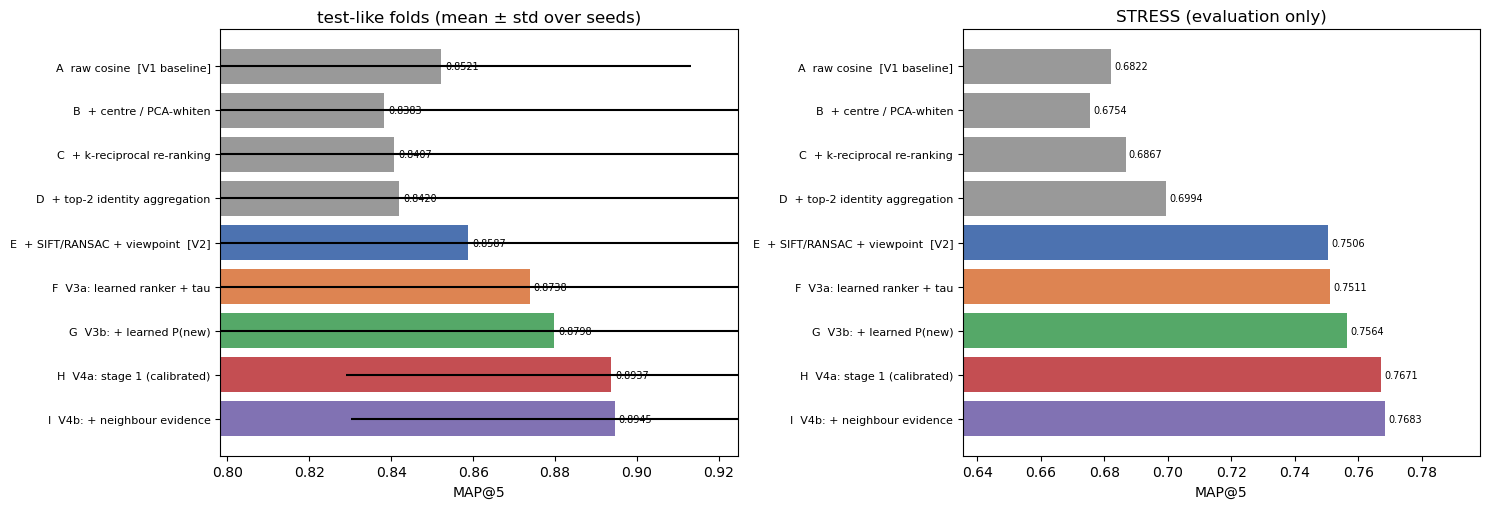

In [19]:
RESULTS_DF = pd.DataFrame(RESULTS)
RESULTS_DF = pd.concat([RESULTS_DF[RESULTS_DF.scheme == s] for s in ALLS]).set_index(["scheme", "version"])
RESULTS_DF.to_csv(os.path.join(OUT_DIR, "results_cv.csv"))
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
display(RESULTS_DF.round(4))

SUMMARY = RESULTS_DF.loc[list(TRS)].groupby("version", sort=False)["MAP@5"].agg(["mean", "std"])
print("\nMAP@5 on the test-like folds, mean / std over %d seed(s):" % len(TRS)); print(SUMMARY.round(4).to_string())
for pref, lab in (("s", "test-like (image-weighted)"), ("r", "rare-identity (thinned galleries)")):
    ss_ = [s_ for s_ in TRS if s_.startswith(pref)]
    if ss_: print(f"\nMAP@5, {lab} schemes {ss_}:"); print(RESULTS_DF.loc[ss_].groupby("version", sort=False)["MAP@5"].mean().round(4).to_string())
if EVS:
    print("\nSTRESS (evaluation only, deliberately much harder than test - read as a lower bound, not an estimate):")
    print(RESULTS_DF.loc[EVS[0]]["MAP@5"].round(4).to_string())

import matplotlib.pyplot as plt
COL = {"A": "#999999", "B": "#999999", "C": "#999999", "D": "#999999", "E": "#4C72B0", "F": "#DD8452", "G": "#55A868", "H": "#C44E52", "I": "#8172B3"}
fig, axs = plt.subplots(1, 2 if EVS else 1, figsize=(15 if EVS else 9, 5.2), squeeze=False)
for ax, (title, vals, err) in zip(axs[0], [("test-like folds (mean ± std over seeds)", SUMMARY["mean"], SUMMARY["std"].fillna(0))] +
                                  ([("STRESS (evaluation only)", RESULTS_DF.loc[EVS[0]]["MAP@5"], None)] if EVS else [])):
    ax.barh(range(len(vals)), vals.values, xerr=None if err is None else err.values, color=[COL.get(v[0], "#999") for v in vals.index])
    ax.set_yticks(range(len(vals))); ax.set_yticklabels(vals.index, fontsize=8); ax.invert_yaxis()
    lo = vals.min(); ax.set_xlim(max(0, lo - 0.04), min(1, vals.max() + 0.03)); ax.set_title(title); ax.set_xlabel("MAP@5")
    for i, v in enumerate(vals.values): ax.text(v + 0.001, i, f"{v:.4f}", va="center", fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "ablation.png"), dpi=130); plt.show()

### Self-check: the vectorised metric equals the plain definition

In [20]:
for s in ALLS:
    lists_chk = make_lists(*FIN_TOP[s], FIN_PNEW[s])
    truth_names = np.where(TCODE[s] >= 0, CLASSES[np.maximum(TCODE[s], 0)], NEW)
    ref = map5([l.split() for l in lists_chk], truth_names)
    assert abs(ref - FIN_RES[s]["ap"].mean()) < 1e-9, (s, ref, FIN_RES[s]["ap"].mean())
    print(f"[{s}] reference MAP@5 on the written-format lists = {ref:.6f}  (matches the vectorised value)")

[s0] reference MAP@5 on the written-format lists = 0.923287  (matches the vectorised value)
[s1] reference MAP@5 on the written-format lists = 0.927788  (matches the vectorised value)
[s2] reference MAP@5 on the written-format lists = 0.927218  (matches the vectorised value)
[r3] reference MAP@5 on the written-format lists = 0.796697  (matches the vectorised value)
[stress] reference MAP@5 on the written-format lists = 0.767079  (matches the vectorised value)


## 8b. Prior shift: what if the test share of new individuals differs from the CV share?
The CV share is controlled (≈ 0.40) but the test share is only weakly identified from similarity alone. The table re-weights the primary CV queries to a different new-individual share and compares the decisions **without** and **with** the prior-shift correction applied (using the true shift). A positive gain means that knowing the share would matter; `PRIOR_SHIFT=auto` only moves towards the estimated band, so it cannot do worse than the band's edge.

In [21]:
def sensitivity_table(scheme=None):
    scheme = scheme or PRIMARY; P, tcode = POOL[scheme], TCODE[scheme]; spa = P["sp"].astype(int)
    top, sc = FIN_TOP[scheme]; pn = FIN_PNEW[scheme]; rows = []
    for pi_ in (0.25, 0.30, 0.40, 0.50, 0.55):
        w = np.zeros(len(tcode))
        for i, sp in enumerate(SPECIES):
            m = spa == i; w[m] = np.where(tcode[m] < 0, pi_ / PI_CV[sp], (1 - pi_) / (1 - PI_CV[sp]))
        base = np.average(per_query_ap(top, sc, pn, tcode)[0], weights=w)
        saved = {k: dict(v) for k, v in PIS.items()}
        for sp in SPECIES: PIS[sp]["use"] = pi_
        sc2, pn2 = prior_adjust(sc, pn, spa)
        for sp in SPECIES: PIS[sp]["use"] = saved[sp]["use"]
        adj = np.average(per_query_ap(top, sc2, pn2, tcode)[0], weights=w)
        rows.append(dict(test_new_share=pi_, MAP_uncorrected=base, MAP_corrected=adj, gain=adj - base))
    return pd.DataFrame(rows).set_index("test_new_share")
SENS = sensitivity_table(); print(f"re-weighted {PRIMARY} queries (CV share {np.mean(list(PI_CV.values())):.2f}):"); print(SENS.round(4).to_string())
SENS.to_csv(os.path.join(OUT_DIR, "prior_shift_sensitivity.csv"))

re-weighted s0 queries (CV share 0.40):
                MAP_uncorrected  MAP_corrected    gain
test_new_share                                        
0.25                     0.9128         0.9130  0.0001
0.30                     0.9162         0.9159 -0.0004
0.40                     0.9230         0.9226 -0.0003
0.50                     0.9297         0.9304  0.0007
0.55                     0.9331         0.9349  0.0018


## 11. Error analysis of the final model (V4)

[s0]
                                                        queries   share  MAP lost
known: correct @2-5 (ranking error)                         214  0.0300    0.0194
known: in candidates but outside top-5 (ranking error)      125  0.0175    0.0175
known: right identity first, but NEW placed above it        246  0.0345    0.0172
new: a known identity ranked above NEW (false match)        203  0.0284    0.0146
known: true identity not retrieved (retrieval miss)          57  0.0080    0.0080
known: correct @1                                          3623  0.5076    0.0000
new: NEW ranked 1st (correct)                              2669  0.3740    0.0000

total MAP lost = 0.0767  (1 - MAP@5)


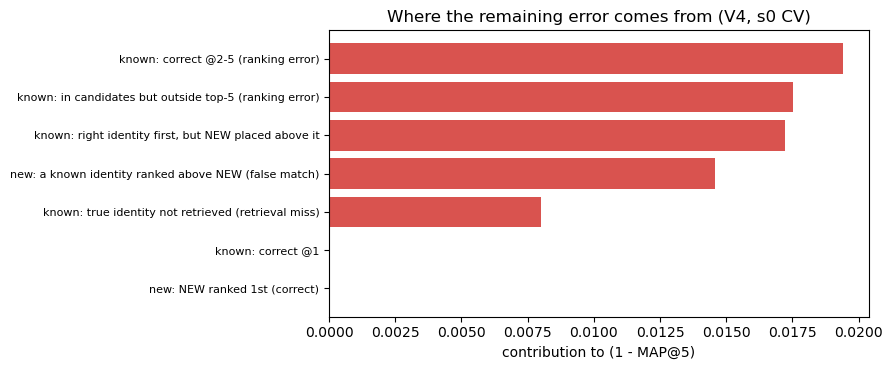

[stress]
                                                        queries   share  MAP lost
known: true identity not retrieved (retrieval miss)         460  0.0642    0.0642
known: in candidates but outside top-5 (ranking error)      374  0.0522    0.0522
known: right identity first, but NEW placed above it        746  0.1041    0.0521
known: correct @2-5 (ranking error)                         486  0.0678    0.0480
new: a known identity ranked above NEW (false match)        224  0.0313    0.0165
new: NEW ranked 1st (correct)                              2867  0.4003    0.0000
known: correct @1                                          2006  0.2801    0.0000

total MAP lost = 0.2329  (1 - MAP@5)


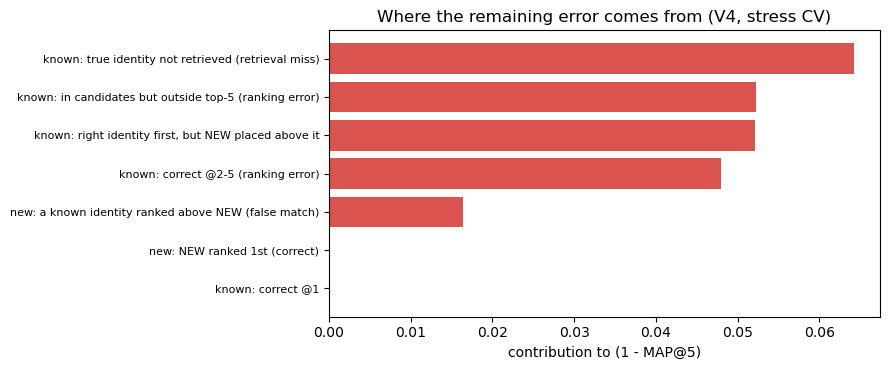

In [22]:
def failure_taxonomy(sch):
    ap, r, pos = FIN_RES[sch]["ap"], FIN_RES[sch]["r"], FIN_RES[sch]["pos"]
    tcode, has_truth = TCODE[sch], HAS[sch]
    new_q = tcode < 0; rank_final = np.where(r >= pos, r + 2, r + 1)
    cat = np.empty(len(ap), dtype=object)
    cat[new_q & (pos == 0)] = "new: NEW ranked 1st (correct)"
    cat[new_q & (pos > 0)]  = "new: a known identity ranked above NEW (false match)"
    kn = ~new_q
    cat[kn & (rank_final == 1)]                        = "known: correct @1"
    cat[kn & (r == 0) & (rank_final == 2)]             = "known: right identity first, but NEW placed above it"
    cat[kn & (rank_final >= 2) & (rank_final <= 5) & ~((r == 0) & (rank_final == 2))] = "known: correct @2-5 (ranking error)"
    cat[kn & (rank_final > 5) & has_truth]             = "known: in candidates but outside top-5 (ranking error)"
    cat[kn & ~has_truth]                               = "known: true identity not retrieved (retrieval miss)"
    tax = pd.DataFrame({"queries": pd.Series(cat).value_counts(), "share": pd.Series(cat).value_counts(normalize=True).round(4)})
    tax["MAP lost"] = [ (1 - ap[cat == c]).sum() / len(ap) for c in tax.index]
    tax = tax.sort_values("MAP lost", ascending=False)
    print(f"[{sch}]"); print(tax.round(4).to_string())
    print("\ntotal MAP lost = %.4f  (1 - MAP@5)" % (1 - ap.mean()))
    fig, ax = plt.subplots(figsize=(9, 3.8)); ax.barh(range(len(tax)), tax["MAP lost"], color="#d9534f")
    ax.set_yticks(range(len(tax))); ax.set_yticklabels(tax.index, fontsize=8); ax.invert_yaxis(); ax.set_xlabel("contribution to (1 - MAP@5)")
    ax.set_title(f"Where the remaining error comes from (V4, {sch} CV)"); savefig(f"failure_taxonomy_{sch}.png")
for sch in (PRIMARY,) + EVS: failure_taxonomy(sch)

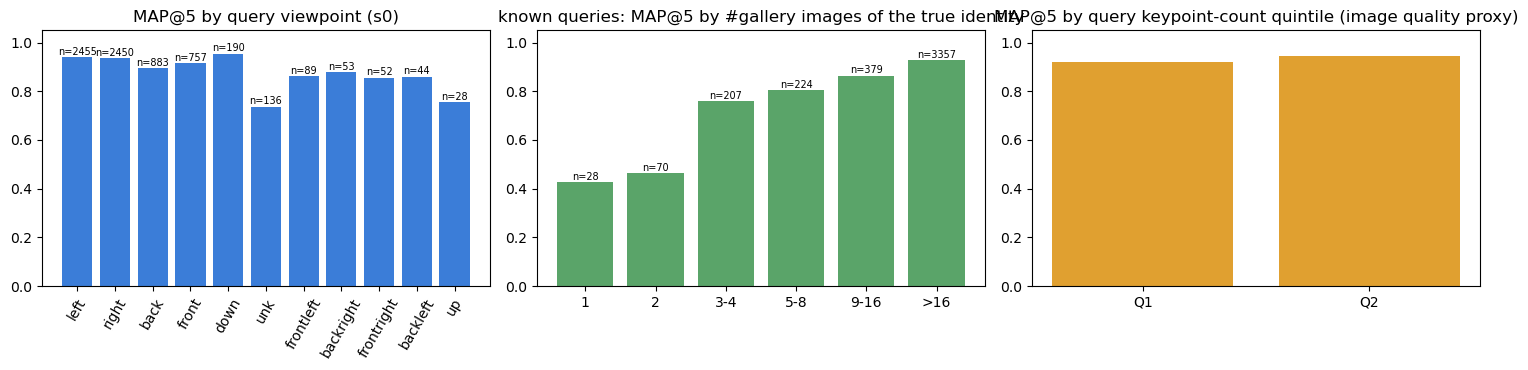

[s0]
                 mean  size
sp      new                
hyena   False  0.8469  1140
        True   0.9442   769
leopard False  0.9139  3125
        True   0.9710  2103


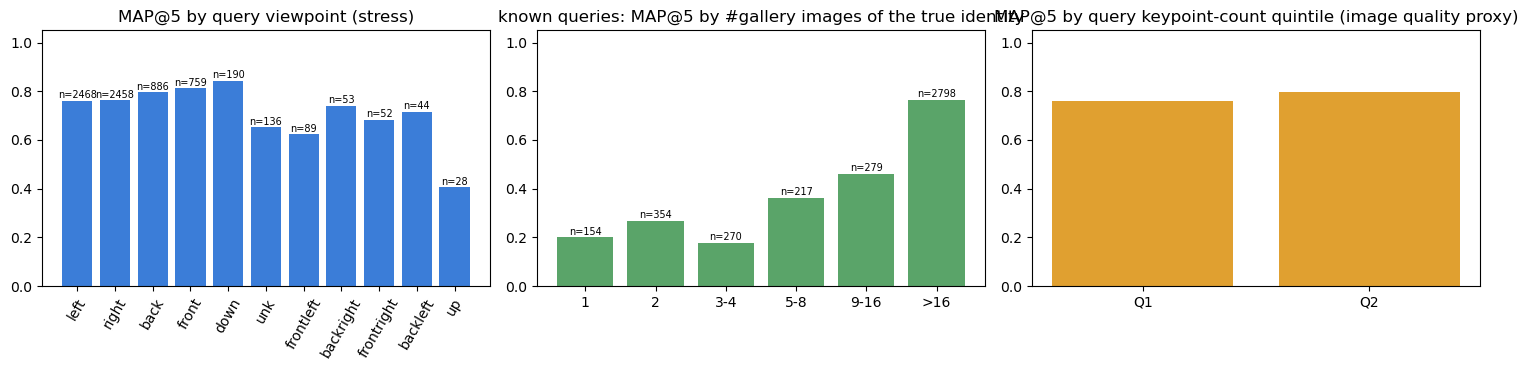

[stress]
                 mean  size
sp      new                
hyena   False  0.4717  1226
        True   0.9553   686
leopard False  0.6828  2846
        True   0.9638  2405


In [23]:
def slice_report(sch):
    ap, new_q, P = FIN_RES[sch]["ap"], TCODE[sch] < 0, POOL[sch]
    tmp = pd.DataFrame({"ident": tr.identity.to_numpy(dtype=object), "fold": FOLDS[sch][0]}); tot = tmp.groupby("ident").size(); infold = tmp.groupby(["ident", "fold"]).size()
    ident_q = tmp.ident.to_numpy()[P["q_rows"]]
    gal_size = tot.reindex(ident_q).to_numpy() - infold.reindex(pd.MultiIndex.from_arrays([ident_q, P["fold"].astype(np.int64)])).to_numpy()
    D_ = pd.DataFrame({"ap": ap, "new": new_q, "vp": np.array(VP_VOCAB)[P["q_vp"]], "kq0": P["kq"][:, 0], "gal": gal_size, "sp": np.array(SPECIES)[P["sp"]]})
    fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
    g = D_.groupby("vp").ap.agg(["mean", "size"]).sort_values("size", ascending=False); axs[0].bar(g.index, g["mean"], color="#3b7dd8"); axs[0].set_title(f"MAP@5 by query viewpoint ({sch})"); axs[0].tick_params(axis="x", rotation=60)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])): axs[0].text(i, m + 0.01, f"n={n}", ha="center", fontsize=7)
    K_ = D_[~D_.new].copy(); K_["bin"] = pd.cut(K_.gal, [0, 1, 2, 4, 8, 16, 10_000], labels=["1", "2", "3-4", "5-8", "9-16", ">16"])
    g2 = K_.groupby("bin", observed=True).ap.agg(["mean", "size"]); axs[1].bar(g2.index.astype(str), g2["mean"], color="#5aa469"); axs[1].set_title("known queries: MAP@5 by #gallery images of the true identity")
    for i, (m, n) in enumerate(zip(g2["mean"], g2["size"])): axs[1].text(i, m + 0.01, f"n={n}", ha="center", fontsize=7)
    D_["kbin"] = pd.qcut(D_.kq0.replace(0, np.nan), 5, duplicates="drop"); g3 = D_.groupby("kbin", observed=True).ap.mean()
    axs[2].bar([f"Q{i+1}" for i in range(len(g3))], g3.values, color="#e0a030"); axs[2].set_title("MAP@5 by query keypoint-count quintile (image quality proxy)")
    for a in axs: a.set_ylim(0, 1.05)
    savefig(f"slices_{sch}.png")
    print(f"[{sch}]"); print(D_.groupby(["sp", "new"]).ap.agg(["mean", "size"]).round(4))
for sch in (PRIMARY,) + EVS: slice_report(sch)

[s0] mean predicted P(new) on CV: 0.380 | true new share: 0.402
[s1] mean predicted P(new) on CV: 0.379 | true new share: 0.406
[s2] mean predicted P(new) on CV: 0.370 | true new share: 0.401
[r3] mean predicted P(new) on CV: 0.486 | true new share: 0.409
[stress] mean predicted P(new) on CV: 0.550 | true new share: 0.432


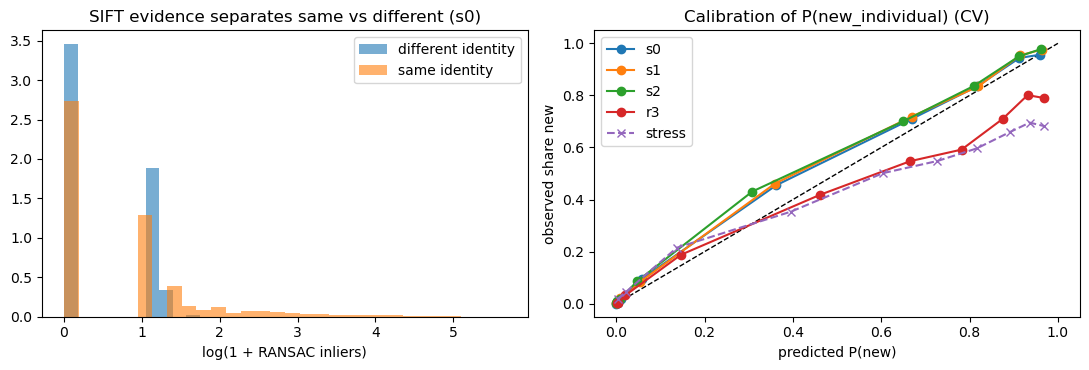

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
P_h, t_h = POOL[PRIMARY], TCODE[PRIMARY]
Mx = min(TOP_M_EFF, P_h["inl"].shape[1]); same_m = (P_h["gc"][:, :Mx] == t_h[:, None]) & (t_h[:, None] >= 0)
li = np.log1p(P_h["inl"][:, :Mx]); kn_rows = (t_h >= 0)[:, None] & np.ones((1, Mx), bool)
axs[0].hist(li[kn_rows & ~same_m], bins=30, alpha=.6, density=True, label="different identity"); axs[0].hist(li[same_m], bins=30, alpha=.6, density=True, label="same identity")
axs[0].set_xlabel("log(1 + RANSAC inliers)"); axs[0].set_title(f"SIFT evidence separates same vs different ({PRIMARY})"); axs[0].legend()
axs[1].plot([0, 1], [0, 1], "k--", lw=1)
for s in ALLS:
    pn = FIN_PNEW[s]; ynew = (TCODE[s] < 0).astype(int); bins = np.quantile(pn, np.linspace(0, 1, 11)); idx = np.clip(np.digitize(pn, bins[1:-1]), 0, 9)
    cal = pd.DataFrame({"pred": pn, "obs": ynew, "b": idx}).groupby("b").mean(); axs[1].plot(cal.pred, cal.obs, "o-" if s in TRS else "x--", label=s)
    print(f"[{s}] mean predicted P(new) on CV: %.3f | true new share: %.3f" % (pn.mean(), ynew.mean()))
axs[1].set_xlabel("predicted P(new)"); axs[1].set_ylabel("observed share new"); axs[1].set_title("Calibration of P(new_individual) (CV)"); axs[1].legend()
savefig("evidence_and_calibration.png")

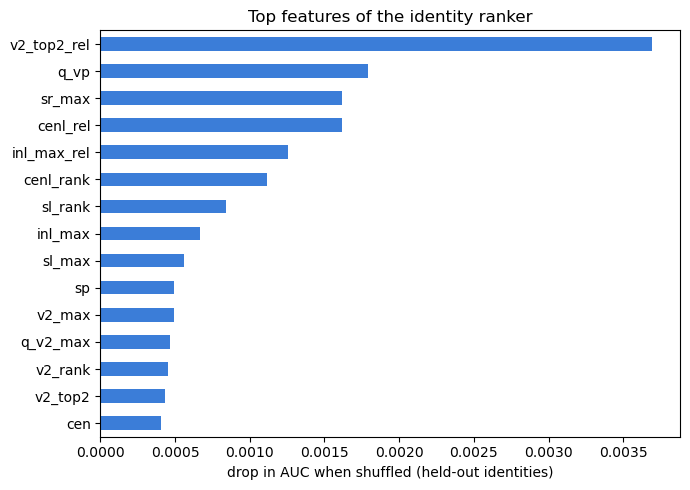

v2_top2_rel    0.0037
q_vp           0.0018
sr_max         0.0016
cenl_rel       0.0016
inl_max_rel    0.0013
cenl_rank      0.0011
sl_rank        0.0008
inl_max        0.0007
sl_max         0.0006
sp             0.0005


In [25]:
# importance measured on HELD-OUT identities (model fold 0), not on the rows the model was fitted on
hold = mf1 == 0; rs = np.random.default_rng(SEED); ev_idx = np.flatnonzero(hold); samp = rs.choice(ev_idx, min(40000, len(ev_idx)), replace=False)
m_id_tmp = fit_hgb(X1[~hold], y1[~hold], ID_FEATS)
pi_imp = permutation_importance(m_id_tmp, X1[samp], y1[samp], scoring="roc_auc", n_repeats=3, random_state=SEED)
imp = pd.Series(pi_imp.importances_mean, index=ID_FEATS).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 5)); imp.head(15)[::-1].plot.barh(ax=ax, color="#3b7dd8"); ax.set_xlabel("drop in AUC when shuffled (held-out identities)"); ax.set_title("Top features of the identity ranker"); savefig("feature_importance.png")
print(imp.head(10).round(4).to_string())

## 12. Final models, test inference and submission files (one per version)

* **V1**: raw cosine, max aggregation, per-species τ (mean of the full-data τ of the test-like seeds).
* **V2**: V2 blend + top-2 aggregation, per-species τ re-tuned on the test-like seeds.
* **V3**: identity ranker and P(new) refit on **all** out-of-fold rows of the test-like seeds (never on the stress scheme).
* **V4**: stage 1 and stage 2 refit the same way; `submission.csv` is written from stage 2 only if `USE_S2` (it must help on every seed), otherwise from stage 1.
* V3/V4 decisions go through the (conservative) prior-shift correction of section 5b when `PRIOR_SHIFT` is `auto` or `force`.

In [26]:
preds_by_version = {}
def to_series(lists, P):
    s = np.empty(len(te), dtype=object); s[P["q_rows"]] = lists; return s
PT = POOL["test"]; nT = len(PT["qid"]); spi = PT["sp"].astype(int)

# V1
top, sc = agg_topk(PT["r_sc"], PT["r_gc"], "max")
preds_by_version["v1"] = to_series(make_lists(top, sc, np.mean([RES_A[s]["taus"] for s in TRS], axis=0)[spi]), PT)
# V2
top, sc = agg_topk(blend(PT, BEST_PARAMS), PT["gc"], BEST_PARAMS["agg"])
preds_by_version["v2"] = to_series(make_lists(top, sc, np.mean([RES_E[s]["taus"] for s in TRS], axis=0)[spi]), PT)
# V3
m_id_v3 = fit_model(X1_v3, y1, ID_FEATS_V3); m_new_v3 = fit_model(Xq_v3, yq, NEW_FEATS_V3)
T_te = identity_table(PT); T_te["p_v3"] = m_id_v3.predict_proba(T_te[ID_FEATS_V3].to_numpy(np.float32))[:, 1]
top_te3, sc_te3 = top_from_table(T_te, nT, "p_v3", 5)
Q_te3 = query_table(PT, T_te, "p_v3"); pnew_te3 = m_new_v3.predict_proba(Q_te3[NEW_FEATS_V3].to_numpy(np.float32))[:, 1]
sc3a, pn3a = prior_adjust(sc_te3, pnew_te3, spi)
preds_by_version["v3"] = to_series(make_lists(top_te3, sc3a, pn3a), PT)
m_id1 = fit_model(X1, y1, ID_FEATS); m_new1 = fit_model(Xq1, yq, NEW_FEATS)
T_te["p"] = m_id1.predict_proba(T_te[ID_FEATS].to_numpy(np.float32))[:, 1]
top_te1, sc_te1 = top_from_table(T_te, nT, "p", 5)
Q_te = query_table(PT, T_te, "p"); pnew_te1 = m_new1.predict_proba(Q_te[NEW_FEATS].to_numpy(np.float32))[:, 1]
sc1a, pn1a = prior_adjust(sc_te1, pnew_te1, spi)
preds_by_version["v4_s1"] = to_series(make_lists(top_te1, sc1a, pn1a), PT)
T_te = add_neighbour_feats(PT, T_te, "p")
m_id2 = fit_model(X2, y2, ID_FEATS2); m_new2 = fit_model(Xq2, yq, NEW_FEATS2)
T_te["p2"] = m_id2.predict_proba(T_te[ID_FEATS2].to_numpy(np.float32))[:, 1]
top_te2, sc_te2 = top_from_table(T_te, nT, "p2", 5)
Q_te2 = query_table(PT, T_te, "p2"); Q_te2["s1_p1"] = Q_te["p1"]; Q_te2["s1_pnew"] = pnew_te1
pnew_te2 = m_new2.predict_proba(Q_te2[NEW_FEATS2].to_numpy(np.float32))[:, 1]
sc2a, pn2a = prior_adjust(sc_te2, pnew_te2, spi)
preds_by_version["v4_s2"] = to_series(make_lists(top_te2, sc2a, pn2a), PT)
log("mean predicted P(new) on TEST: V3 %.3f | stage1 %.3f | stage2 %.3f   (CV true new share: %.3f)" % (pnew_te3.mean(), pnew_te1.mean(), pnew_te2.mean(), yq.mean()))
print("  by species (stage 2):", {s: round(float(pnew_te2[PT['sp'] == i].mean()), 3) for i, s in enumerate(SPECIES)})
log("prior-shift correction (%s): test new-share used per species %s | CV prior %s" % (PRIOR_SHIFT, {k: round(v["use"], 3) for k, v in PIS.items()}, {k: round(v, 3) for k, v in PI_CV.items()}))

[  2864s] mean predicted P(new) on TEST: V3 0.366 | stage1 0.376 | stage2 0.391   (CV true new share: 0.405)
  by species (stage 2): {'hyena': 0.401, 'leopard': 0.383}
[  2864s] prior-shift correction (off): test new-share used per species {'hyena': 0.404, 'leopard': 0.405} | CV prior {'hyena': 0.404, 'leopard': 0.405}


In [30]:
ss_path = f"{DATA_DIR}/sample_submission.csv"
ss = pd.read_csv(ss_path) if os.path.exists(ss_path) else None
ident_species = tr.drop_duplicates("identity").set_index("identity").species.to_dict(); test_species = te.set_index("id").species.to_dict()

prev = next((p for p in [os.environ.get("PREV_SUB"), "submission_v3.csv", os.path.join(DATA_DIR, "submission_v3.csv"), "submission.csv", os.path.join(DATA_DIR, "submission.csv")] if p and os.path.isfile(p)), None)
old = pd.read_csv(prev).set_index("id").predictions.str.split().str[0] if prev else None

def check_and_write(tag, arr):
    sub = pd.DataFrame({"id": te.id.to_numpy(), "predictions": arr})
    assert not sub.predictions.isna().any(), "NaN predictions"
    if ss is not None: assert len(sub) == len(ss) and set(sub.id) == set(ss.id) and sub.id.is_unique, "ids differ from sample_submission"
    nr = Counter()
    for i, p in zip(sub.id, sub.predictions):
        labs = p.split(); assert 1 <= len(labs) <= 5 and len(set(labs)) == len(labs), f"bad label count/dupes in {i}"
        for l in labs: assert l == NEW or (l in ident_species and ident_species[l] == test_species[i]), f"invalid label {l} for {i}"
        nr[labs.index(NEW) + 1 if NEW in labs else 0] += 1
    path = os.path.join(OUT_DIR, f"submission_{tag}.csv"); sub.to_csv(path, index=False)
    print(f"{tag}: OK -> {path} | new@1 rate {nr[1] / len(sub):.1%} | NEW absent from list: {nr[0]}")
    return sub

subs = {k: check_and_write(k, v) for k, v in preds_by_version.items()}
print(subs["v4_s2"].sample(min(6, len(te)), random_state=0).to_string(index=False))
chosen = {"v1": "v1", "v2": "v2", "v3": "v3", "v4": "v4_s2" if USE_S2 else "v4_s1"}[SUBMIT_VERSION]
subs[chosen].to_csv(os.path.join(OUT_DIR, "submission.csv"), index=False)
print(f">>> submission.csv written from version {chosen.upper()}")

if old is not None:
    for k, s in subs.items():
        cur = s.set_index("id").predictions.str.split().str[0]; common = old.index.intersection(cur.index)
        print(f"top-1 agreement of {k} with previous {prev}: {(old[common] == cur[common]).mean():.1%}")

v1: OK -> out_v6\submission_v1.csv | new@1 rate 49.1% | NEW absent from list: 0
v2: OK -> out_v6\submission_v2.csv | new@1 rate 39.7% | NEW absent from list: 0
v3: OK -> out_v6\submission_v3.csv | new@1 rate 42.9% | NEW absent from list: 0
v4_s1: OK -> out_v6\submission_v4_s1.csv | new@1 rate 42.7% | NEW absent from list: 0
v4_s2: OK -> out_v6\submission_v4_s2.csv | new@1 rate 42.7% | NEW absent from list: 0
      id                                    predictions
te_02465 HYE0236 new_individual HYE0179 HYE0346 HYE0619
te_00689 new_individual LEO0486 LEO0142 LEO0549 LEO0469
te_02684 new_individual HYE0675 HYE0126 HYE0350 HYE0512
te_00992 HYE0524 new_individual HYE0044 HYE0167 HYE0653
te_00617 HYE0188 HYE0125 new_individual HYE0677 HYE0400
te_00228 new_individual LEO0028 LEO0147 LEO0463 LEO0386
>>> submission.csv written from version V4_S1
top-1 agreement of v1 with previous submission_v3.csv: 83.6%
top-1 agreement of v2 with previous submission_v3.csv: 90.6%
top-1 agreement of v3 with p